# PPMI Modality Analysis: Genetics & Molecular Risk
**Notebook**: `eda_pca_genetics.ipynb`  
**Modality Group**: `genetics` (6 Scoped Analyzable Units)  
**Authoritative Scope**: `docs/important_modality_files.md`  
**Cohort Policy (Revision 4)**: Parkinson's disease (`PD`) and Healthy Controls (`HC`) Only  
**PCA Architecture**: Shared-space class-balanced component space fit on 1 deterministic record per participant  
**Governance Framework**: Codex Supervisory Review & `AGENTS.md` Task `EDA-PCA-001`  

---

## Modality Overview
Consensus Parkinson's gene variants (LRRK2, GBA, SNCA, APOE), validated polygenic risk scores (PRS), deep targeted resequencing (Project 9001), Whole-Genome Sequencing (WGS) variant calls, and family pedigree history.

### Scientific & Governance Invariants
1. **Target Cohort Restriction**: Analytical populations and PCA models are restricted exclusively to verified **Parkinson's disease (`PD`)** and **Healthy Controls (`HC`)**. Excluded classes (SWEDD, prodromal, genetic non-motor carriers) are filtered out prior to analysis. Cohort labels and disease staging fields never enter the PCA feature matrix.
2. **Participant-Level Shared-Space PCA**: For eligible participant-level tables, repeated visits are resolved to 1 record per participant (baseline preferred with stable tie-breaking and completeness checks). PCA and preprocessing (median imputation, scaling) are fit exclusively on a shared, deterministically class-balanced sample ($k = \min(N_{PD}, N_{HC})$, sampled via SHA-256 hash ranking) to reduce direct sample-count influence on component orientation, and all target participants are projected into this identical space.
3. **Comprehensive Committed EDA (Correction C1 / R4-02)**: Exact schemas with variable roles, missingness, duplicate rows, observation grain, numeric skewness, Tukey IQR and z-score outlier metrics, and categorical frequency summaries are visibly rendered in this notebook and committed directly to disk.
4. **Privacy-Safe Displays (Correction C3 / R4-05)**: Scree plots, loadings tables, and 2x2 side-by-side PD vs HC hexbin density score plots with cell suppression ($< 5$ observations masked) and outlier disclosures.
5. **Committed State Reproducibility (Correction C4 / R4-04)**: Loads directly from committed reports (`EDA/outputs/reports/`) using repository-relative POSIX paths with zero dependence on ignored cache.

In [1]:
import os
import sys
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

# Styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.size'] = 10

# Resolve repository root
repo_root = Path.cwd().resolve()
if (repo_root / "EDA" / "src").exists():
    sys.path.insert(0, str(repo_root / "EDA" / "src"))
elif (repo_root.parent / "EDA" / "src").exists():
    repo_root = repo_root.parent
    sys.path.insert(0, str(repo_root / "EDA" / "src"))

from ppmi_pipeline.reporting.privacy import PrivacyGuard

print(f"Environment initialized. Modality: 'genetics', Dynamic repository root: ppmi")

Environment initialized. Modality: 'genetics', Dynamic repository root: ppmi


## 1. Scoped Analyzable Units in Genetics & Molecular Risk
The authoritative catalog assigns exactly **6 analyzable unit(s)** to this modality domain.

In [2]:
manifest_path = repo_root / "EDA" / "outputs" / "reports" / "priority_eda_pca_manifest.json"
with open(manifest_path, "r", encoding="utf-8") as f:
    manifest_data = json.load(f)

mod_units = [u for u in manifest_data["units"] if u.get("modality_group") == 'genetics']

inv_rows = []
for unit_entry in mod_units:
    sheet_suffix = (" -> [" + str(unit_entry.get("sheet_name")) + "]") if unit_entry.get("sheet_name") else ""
    pca_stat_str = ("COMPLETED (" + str(unit_entry.get("pca_included_features_count", 0)) + " feats)") if unit_entry.get("pca_status") == "COMPLETED" else str(unit_entry.get("pca_skip_reason"))
    inv_rows.append({
        "Unit Slug": unit_entry["unit_slug"],
        "Filename / Sheet": str(unit_entry.get("declared_filename")) + sheet_suffix,
        "Physical Exists": "Yes" if unit_entry.get("physical_exists") else "No (Absent)",
        "EDA Status": unit_entry.get("eda_status"),
        "PCA Status": unit_entry.get("pca_status"),
        "PCA Reason / Features": pca_stat_str
    })

inv_df = pd.DataFrame(inv_rows)
display(inv_df)
print(f"Total units cataloged: {len(inv_df)} | EDA Completed: {(inv_df['EDA Status'] == 'COMPLETED').sum()} | PCA Completed: {(inv_df['PCA Status'] == 'COMPLETED').sum()}")

,Unit Slug,Filename / Sheet,Physical Exists,EDA Status,PCA Status,PCA Reason / Features
0,subject_characteristics_iu_genetic_consensus_2...,iu_genetic_consensus_20251025_09Nov2026.csv,Yes,COMPLETED,SKIPPED,Insufficient usable numeric analytical feature...
1,subject_characteristics_Polygenic_Risk_Scores_...,Polygenic_Risk_Scores_09Nov2026.csv,Yes,COMPLETED,COMPLETED,COMPLETED (16 feats)
2,subject_characteristics_Family_History_09Nov20...,Family_History_09Nov2026.csv,Yes,COMPLETED,SKIPPED,Insufficient usable numeric analytical feature...
3,subject_characteristics_Genotypes_for_Polygeni...,Genotypes_for_Polygenic_Risk_Scores_09Nov2026.csv,Yes,COMPLETED,SKIPPED,Insufficient usable numeric analytical feature...
4,subject_characteristics_PPMI_Project_9001_2025...,PPMI_Project_9001_20250624_09Nov2026.csv,Yes,COMPLETED,COMPLETED,COMPLETED (106 feats)
5,subject_characteristics_PPMI_PD_Variants_Genet...,PPMI_PD_Variants_Genetic_Status_WGS_20180921.csv,Yes,COMPLETED,COMPLETED,COMPLETED (65 feats)


Total units cataloged: 6 | EDA Completed: 6 | PCA Completed: 3


---
## 2.1. Unit: `iu_genetic_consensus_20251025_09Nov2026.csv` 
- **Unit Slug**: `subject_characteristics_iu_genetic_consensus_20251025_09Nov2026_csv`
- **Source Path**: `subject_characteristics/iu_genetic_consensus_20251025_09Nov2026.csv`
- **Committed Unit Artifact**: [`subject_characteristics_iu_genetic_consensus_20251025_09Nov2026_csv.json`](../EDA/outputs/reports/units/subject_characteristics_iu_genetic_consensus_20251025_09Nov2026_csv.json)
- **Declared Observation Grain**: `(PATNO,)`
- **Selection Tier**: `Primary EDA` | **Role**: `Consensus genetic determinations across all sequencing runs: *LRRK2* mutations (G2019S, R1441G), *GBA* variants (N370S, L444P, E326K), *SNCA* mutations/multiplications, *PRKN*, *PINK1*, and *APOE* ($\varepsilon2/\varepsilon3/\varepsilon4$) diplotypes.`
- **Terminal Statuses**: EDA: `COMPLETED` | PCA: `SKIPPED`

UNIT ANALYSIS: subject_characteristics/iu_genetic_consensus_20251025_09Nov2026.csv
EDA Status: COMPLETED | PCA Status: SKIPPED
Dimensions: 1,661 analyzed rows x 22 columns
Observation Grain: Single observation per participant (PATNO)
Candidate Primary Keys: [['PATNO']]

Target Cohort Filtering Denominators:
  - Initial Rows: 6,265 (6,265 participants)
  - PD Retained:  1,366 rows (1,366 participants)
  - HC Retained:  295 rows (295 participants)
  - Non-Target Excluded: 1,944 rows (SWEDD/Prodromal)
  - Unmatched Excluded:  2,660 rows

Exact Variable Schema & Storage Types (22 columns):


,name,dtype,missing_count,missing_percent,distinct_count,variable_role
0,PATNO,int64,0,0.0%,"1,661",Identifier
1,CLIA,object,0,0.0%,2,Categorical / Text
2,GWAS,object,0,0.0%,2,Categorical / Text
3,WES,object,0,0.0%,2,Categorical / Text
4,WGS,object,0,0.0%,2,Categorical / Text
5,SVs,object,0,0.0%,2,Categorical / Text
6,SANGER,object,0,0.0%,2,Categorical / Text
7,IU_Fingerprint,object,0,0.0%,2,Categorical / Text
8,RNASEQ,object,0,0.0%,2,Categorical / Text
9,RNASEQ_VIS,int64,0,0.0%,6,Analytical Numeric Measurement



Variable Role Distribution Summary:


,Count
variable_role,
Categorical / Text,18
Analytical Numeric Measurement,2
Identifier,1
Cohort / Stratification Label,1



Missingness & Duplicate Quality Evidence:
  - Total Missing Cells: 2,814 / 36,542 (7.70%)
  - Duplicate Rows Count: 0
  - Columns with Missing Values (11 total, top 8):


,name,missing_count,missing_percent,variable_role
20,NOTES,"1,414",85.1%,Categorical / Text
17,PRKN,233,14.0%,Categorical / Text
15,VPS35,230,13.8%,Categorical / Text
19,PINK1,230,13.8%,Categorical / Text
18,PARK7,230,13.8%,Categorical / Text
16,SNCA,229,13.8%,Categorical / Text
14,GBA,228,13.7%,Categorical / Text
10,APOE,14,0.8%,Categorical / Text


... (4 outputs left out)

  * Feature: WES (Distinct Categories: 2)


,category,row_count
0,-,"1,084"
1,X,577



Numeric Summaries & Outlier Diagnostics (2 continuous/discrete features):


,variable,mean,std,min,median,max,skewness,shape,iqr_outliers_count,zscore_outliers_count
0,RNASEQ_VIS,1.868,2.101,0.0,0.0,5.0,0.412,Approximately symmetric,0,0
1,PATHVAR_COUNT,0.227,0.452,0.0,0.0,2.0,1.768,Strongly skewed (positive),352,24


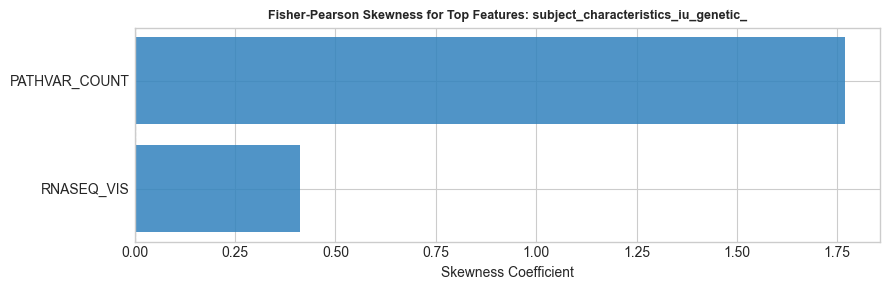

In [3]:
# Load committed unit artifact
unit_json_path = repo_root / "EDA" / "outputs" / "reports" / "units" / "subject_characteristics_iu_genetic_consensus_20251025_09Nov2026_csv.json"
with open(unit_json_path, "r", encoding="utf-8") as f:
    unit_data = json.load(f)

print("=" * 80)
print(f"UNIT ANALYSIS: subject_characteristics/iu_genetic_consensus_20251025_09Nov2026.csv")
print("=" * 80)
print(f"EDA Status: {unit_data['eda_status']} | PCA Status: {unit_data['pca_status']}")

if unit_data.get("eda_status") == "UNREADABLE":
    print(f"UNREADABLE EVIDENCE: {unit_data.get('eda_unreadable_evidence')}")
else:
    eda = unit_data["eda_diagnostics"]
    print(f"Dimensions: {eda['row_count']:,} analyzed rows x {eda['column_count']} columns")
    print(f"Observation Grain: {eda['observation_grain']}")
    print(f"Candidate Primary Keys: {eda.get('candidate_primary_keys', [])}")

    # Cohort Denominator Evidence
    cohort_ev = eda.get("cohort_filter_evidence")
    if cohort_ev and cohort_ev.get("has_participant_data"):
        print("\nTarget Cohort Filtering Denominators:")
        print(f"  - Initial Rows: {cohort_ev.get('total_rows_pre_filter', 0):,} ({cohort_ev.get('distinct_participants_pre_filter', 0):,} participants)")
        print(f"  - PD Retained:  {cohort_ev.get('pd_rows_retained', 0):,} rows ({cohort_ev.get('pd_participants_retained', 0):,} participants)")
        print(f"  - HC Retained:  {cohort_ev.get('hc_rows_retained', 0):,} rows ({cohort_ev.get('hc_participants_retained', 0):,} participants)")
        print(f"  - Non-Target Excluded: {cohort_ev.get('nontarget_rows_excluded', 0):,} rows (SWEDD/Prodromal)")
        print(f"  - Unmatched Excluded:  {cohort_ev.get('unmatched_rows_excluded', 0):,} rows")

    # 1. Exact Column Schema & Types Table
    cols_df = pd.DataFrame(eda["column_profiles"])
    role_col = "variable_role" if "variable_role" in cols_df.columns else "role"
    schema_cols = [c for c in ["name", "dtype", "missing_count", "missing_percent", "distinct_count", role_col] if c in cols_df.columns]
    schema_view = cols_df[schema_cols].copy()
    if "missing_count" in schema_view.columns:
        schema_view["missing_count"] = schema_view["missing_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "distinct_count" in schema_view.columns:
        schema_view["distinct_count"] = schema_view["distinct_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "missing_percent" in schema_view.columns:
        schema_view["missing_percent"] = schema_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v) if pd.notna(v) else "-")

    print(f"\nExact Variable Schema & Storage Types ({len(cols_df)} columns):")
    if len(schema_view) <= 25:
        display(schema_view)
    else:
        print(f"Showing first 20 of {len(schema_view)} columns (complete schema committed to subject_characteristics_iu_genetic_consensus_20251025_09Nov2026_csv.json):")
        display(schema_view.head(20))

    print("\nVariable Role Distribution Summary:")
    display(cols_df[role_col].value_counts().to_frame("Count"))

    # 2. Missingness and Duplicate Quality Evidence
    print(f"\nMissingness & Duplicate Quality Evidence:")
    print(f"  - Total Missing Cells: {eda['total_missing_cells']:,} / {eda['row_count']*eda['column_count']:,} ({eda['overall_missing_percent']:.2f}%)")
    print(f"  - Duplicate Rows Count: {eda['duplicate_rows_count']}")
    high_missing = cols_df[cols_df["missing_percent"] > 0].sort_values("missing_percent", ascending=False)
    if not high_missing.empty:
        print(f"  - Columns with Missing Values ({len(high_missing)} total, top 8):")
        missing_view = high_missing[["name", "missing_count", "missing_percent", role_col]].head(8).copy()
        missing_view["missing_count"] = missing_view["missing_count"].apply(lambda v: "{:,}".format(int(v)))
        missing_view["missing_percent"] = missing_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v))
        display(missing_view)
    else:
        print("  - Zero missing values detected across all columns.")

    # 3. Categorical Variable Frequency Summaries (<5 Suppressed)
    cat_summaries = eda.get("categorical_summaries", [])
    if cat_summaries:
        print(f"\nCategorical Variable Frequency Distributions ({len(cat_summaries)} variables profiled):")
        for cat_item in cat_summaries[:3]:
            var_name = cat_item.get("variable")
            freq_df = pd.DataFrame(cat_item.get("frequencies", []))
            print(f"  * Feature: {var_name} (Distinct Categories: {cat_item.get('distinct_count')})")
            if not freq_df.empty:
                freq_view = freq_df.copy()
                if "category" in freq_view.columns:
                    freq_view["category"] = freq_view["category"].apply(lambda c: "'" + str(c) + "'" if str(c).strip().upper() in ["ID", "PATNO", "SUBJID", "SUBJECT", "PARTICIPANT", "RECORD", "SAMPLE", "CASE", "PID", "RID"] else str(c))
                if "row_count" in freq_view.columns:
                    freq_view["row_count"] = freq_view["row_count"].apply(lambda v: "{:,}".format(int(v)) if isinstance(v, (int, float)) and pd.notna(v) else str(v))
                display(freq_view)
    else:
        print("\nCategorical Frequency Summaries: No multi-level categorical features for this unit.")

    # 4. Outlier and Numeric Summaries (Fisher-Pearson Skewness & Tukey IQR / Z-Score Diagnostics)
    if eda.get("numeric_summaries"):
        num_df = pd.DataFrame(eda["numeric_summaries"])
        print(f"\nNumeric Summaries & Outlier Diagnostics ({len(num_df)} continuous/discrete features):")
        var_col = "variable" if "variable" in num_df.columns else "name"
        cols_to_show = [c for c in [var_col, "mean", "std", "min", "median", "max", "skewness", "shape", "iqr_outliers_count", "zscore_outliers_count"] if c in num_df.columns]
        num_view = num_df[cols_to_show].copy()
        for count_col in ["iqr_outliers_count", "zscore_outliers_count"]:
            if count_col in num_view.columns:
                num_view[count_col] = num_view[count_col].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
        if len(num_view) <= 12:
            display(num_view)
        else:
            print(f"Showing top 10 of {len(num_view)} features (full distribution profiles in subject_characteristics_iu_genetic_consensus_20251025_09Nov2026_csv.json):")
            display(num_view.head(10))

    # 5. Exploratory Data Visualization
    if eda.get("numeric_summaries") and len(eda["numeric_summaries"]) >= 2:
        top_num = pd.DataFrame(eda["numeric_summaries"]).head(6)
        var_col = "variable" if "variable" in top_num.columns else "name"
        fig, ax = plt.subplots(figsize=(9, 3.0))
        ax.barh(top_num[var_col], top_num["skewness"], color="#3182bd", alpha=0.85)
        ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
        ax.set_title(f"Fisher-Pearson Skewness for Top Features: subject_characteristics_iu_genetic_", fontsize=9, fontweight="bold")
        ax.set_xlabel("Skewness Coefficient")
        plt.tight_layout()
        plt.show()
    elif cat_summaries and cat_summaries[0].get("frequencies"):
        first_cat = cat_summaries[0]
        cat_freq_df = pd.DataFrame(first_cat["frequencies"])
        valid_freqs = cat_freq_df[cat_freq_df["row_count"] != "<5 (Suppressed)"].copy()
        if not valid_freqs.empty and len(valid_freqs) >= 2:
            fig, ax = plt.subplots(figsize=(8, 2.5))
            ax.barh(valid_freqs["category"].astype(str), pd.to_numeric(valid_freqs["row_count"]), color="#31a354", alpha=0.85)
            ax.set_title(f"Categorical Frequencies: {first_cat['variable']}", fontsize=9, fontweight="bold")
            ax.set_xlabel("Participant Row Count")
            plt.tight_layout()
            plt.show()

### Principal Component Analysis: Deterministic Skip
- **Status**: `SKIPPED`
- **Deterministic Skip Reason**: `Insufficient usable numeric analytical features (0 < 2)`
- **Methodological Justification**: This dataset does not meet the scientific prerequisites for multivariate PCA (e.g. lacks $\ge 2$ continuous analytical measurements, is an unpivoted single-measurement log, represents cell repository inventory, or lacks adequate two-class participant coverage).

In [4]:
pca_res = unit_data.get("pca_results") or {}
skip_reason = pca_res.get("skip_reason") or unit_data.get("pca_skip_reason")
print(f"PCA Skip Reason: {skip_reason}")
print(f"Features Evaluated: {pca_res.get('feature_count', 0)} included, {pca_res.get('excluded_features_count', 0)} excluded")
if pca_res.get("excluded_features"):
    ex_df = pd.DataFrame(pca_res["excluded_features"][:10])
    print("\nExcluded Variables Sample:")
    display(ex_df)

PCA Skip Reason: Insufficient usable numeric analytical features (0 < 2)
Features Evaluated: 0 included, 22 excluded

Excluded Variables Sample:


,feature_name,reason
0,PATNO,Sequencing assay inventory catalog; binary var...
1,CLIA,Sequencing assay inventory catalog; binary var...
2,GWAS,Sequencing assay inventory catalog; binary var...
3,WES,Sequencing assay inventory catalog; binary var...
4,WGS,Sequencing assay inventory catalog; binary var...
5,SVs,Sequencing assay inventory catalog; binary var...
6,SANGER,Sequencing assay inventory catalog; binary var...
7,IU_Fingerprint,Sequencing assay inventory catalog; binary var...
8,RNASEQ,Sequencing assay inventory catalog; binary var...
9,RNASEQ_VIS,Sequencing assay inventory catalog; binary var...


---
## 2.2. Unit: `Polygenic_Risk_Scores_09Nov2026.csv` 
- **Unit Slug**: `subject_characteristics_Polygenic_Risk_Scores_09Nov2026_csv`
- **Source Path**: `subject_characteristics/Polygenic_Risk_Scores_09Nov2026.csv`
- **Committed Unit Artifact**: [`subject_characteristics_Polygenic_Risk_Scores_09Nov2026_csv.json`](../EDA/outputs/reports/units/subject_characteristics_Polygenic_Risk_Scores_09Nov2026_csv.json)
- **Declared Observation Grain**: `(PATNO,)`
- **Selection Tier**: `Primary EDA` | **Role**: `Validated Parkinson's Polygenic Risk Scores (PRS) including META5 effect sizes, GP2 European PRS, and GP2 multi-ancestry risk estimates.`
- **Terminal Statuses**: EDA: `COMPLETED` | PCA: `COMPLETED`

UNIT ANALYSIS: subject_characteristics/Polygenic_Risk_Scores_09Nov2026.csv
EDA Status: COMPLETED | PCA Status: COMPLETED
Dimensions: 1,422 analyzed rows x 18 columns
Observation Grain: Single observation per participant (PATNO)
Candidate Primary Keys: [['PATNO']]

Target Cohort Filtering Denominators:
  - Initial Rows: 2,996 (2,996 participants)
  - PD Retained:  1,152 rows (1,152 participants)
  - HC Retained:  270 rows (270 participants)
  - Non-Target Excluded: 1,441 rows (SWEDD/Prodromal)
  - Unmatched Excluded:  133 rows

Exact Variable Schema & Storage Types (18 columns):


,name,dtype,missing_count,missing_percent,distinct_count,variable_role
0,PATNO,int64,0,0.0%,"1,422",Identifier
1,GP2_proxy_PGS,float64,0,0.0%,"1,412",Analytical Numeric Measurement
2,GP2_proxy_AC,int64,0,0.0%,6,Analytical Numeric Measurement
3,GP2_PGS,float64,0,0.0%,"1,411",Analytical Numeric Measurement
4,GP2_AC,int64,0,0.0%,6,Analytical Numeric Measurement
5,META5_excl_LRRK2_GBA_PGS,float64,0,0.0%,"1,396",Analytical Numeric Measurement
6,META5_excl_LRRK2_GBA_AC,int64,0,0.0%,4,Analytical Numeric Measurement
7,META5_PGS,float64,0,0.0%,"1,401",Analytical Numeric Measurement
8,META5_AC,int64,0,0.0%,4,Analytical Numeric Measurement
9,META5_proxy_excl_GBA_PGS,float64,0,0.0%,"1,407",Analytical Numeric Measurement



Variable Role Distribution Summary:


,Count
variable_role,
Analytical Numeric Measurement,16
Identifier,1
Cohort / Stratification Label,1



Missingness & Duplicate Quality Evidence:
  - Total Missing Cells: 0 / 25,596 (0.00%)
  - Duplicate Rows Count: 0
  - Zero missing values detected across all columns.

Categorical Variable Frequency Distributions (1 variables profiled):
  * Feature: TARGET_COHORT_STRATIFICATION (Distinct Categories: 2)


,category,row_count
0,PD,"1,152"
1,HC,270



Numeric Summaries & Outlier Diagnostics (16 continuous/discrete features):
Showing top 10 of 16 features (full distribution profiles in subject_characteristics_Polygenic_Risk_Scores_09Nov2026_csv.json):


,variable,mean,std,min,median,max,skewness,shape,iqr_outliers_count,zscore_outliers_count
0,GP2_proxy_PGS,0.003,0.003,-0.004,0.002,0.023,1.542,Strongly skewed (positive),160,15
1,GP2_proxy_AC,310.376,1.270,302.000,310.000,312.000,-0.774,Moderately skewed (negative),18,18
2,GP2_PGS,0.003,0.003,-0.005,0.003,0.022,1.533,Strongly skewed (positive),156,14
3,GP2_AC,310.305,1.184,302.000,310.000,312.000,-0.482,Approximately symmetric,6,6
4,META5_excl_LRRK2_GBA_PGS,-0.003,0.004,-0.016,-0.003,0.008,-0.031,Approximately symmetric,10,1
5,META5_excl_LRRK2_GBA_AC,160.533,0.975,156.000,160.000,162.000,0.315,Approximately symmetric,5,5
6,META5_PGS,-0.008,0.006,-0.023,-0.009,0.025,1.119,Strongly skewed (positive),93,13
7,META5_AC,174.519,0.997,170.000,174.000,176.000,0.223,Approximately symmetric,5,5
8,META5_proxy_excl_GBA_PGS,-0.001,0.006,-0.015,-0.002,0.033,1.260,Strongly skewed (positive),117,13
9,META5_proxy_excl_GBA_AC,168.530,0.980,164.000,168.000,170.000,0.295,Approximately symmetric,5,5


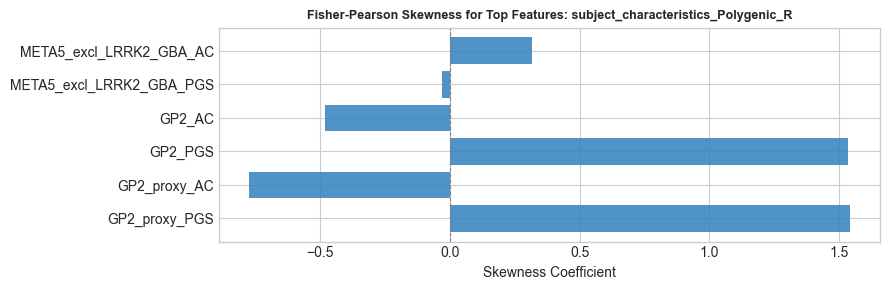

In [5]:
# Load committed unit artifact
unit_json_path = repo_root / "EDA" / "outputs" / "reports" / "units" / "subject_characteristics_Polygenic_Risk_Scores_09Nov2026_csv.json"
with open(unit_json_path, "r", encoding="utf-8") as f:
    unit_data = json.load(f)

print("=" * 80)
print(f"UNIT ANALYSIS: subject_characteristics/Polygenic_Risk_Scores_09Nov2026.csv")
print("=" * 80)
print(f"EDA Status: {unit_data['eda_status']} | PCA Status: {unit_data['pca_status']}")

if unit_data.get("eda_status") == "UNREADABLE":
    print(f"UNREADABLE EVIDENCE: {unit_data.get('eda_unreadable_evidence')}")
else:
    eda = unit_data["eda_diagnostics"]
    print(f"Dimensions: {eda['row_count']:,} analyzed rows x {eda['column_count']} columns")
    print(f"Observation Grain: {eda['observation_grain']}")
    print(f"Candidate Primary Keys: {eda.get('candidate_primary_keys', [])}")

    # Cohort Denominator Evidence
    cohort_ev = eda.get("cohort_filter_evidence")
    if cohort_ev and cohort_ev.get("has_participant_data"):
        print("\nTarget Cohort Filtering Denominators:")
        print(f"  - Initial Rows: {cohort_ev.get('total_rows_pre_filter', 0):,} ({cohort_ev.get('distinct_participants_pre_filter', 0):,} participants)")
        print(f"  - PD Retained:  {cohort_ev.get('pd_rows_retained', 0):,} rows ({cohort_ev.get('pd_participants_retained', 0):,} participants)")
        print(f"  - HC Retained:  {cohort_ev.get('hc_rows_retained', 0):,} rows ({cohort_ev.get('hc_participants_retained', 0):,} participants)")
        print(f"  - Non-Target Excluded: {cohort_ev.get('nontarget_rows_excluded', 0):,} rows (SWEDD/Prodromal)")
        print(f"  - Unmatched Excluded:  {cohort_ev.get('unmatched_rows_excluded', 0):,} rows")

    # 1. Exact Column Schema & Types Table
    cols_df = pd.DataFrame(eda["column_profiles"])
    role_col = "variable_role" if "variable_role" in cols_df.columns else "role"
    schema_cols = [c for c in ["name", "dtype", "missing_count", "missing_percent", "distinct_count", role_col] if c in cols_df.columns]
    schema_view = cols_df[schema_cols].copy()
    if "missing_count" in schema_view.columns:
        schema_view["missing_count"] = schema_view["missing_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "distinct_count" in schema_view.columns:
        schema_view["distinct_count"] = schema_view["distinct_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "missing_percent" in schema_view.columns:
        schema_view["missing_percent"] = schema_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v) if pd.notna(v) else "-")

    print(f"\nExact Variable Schema & Storage Types ({len(cols_df)} columns):")
    if len(schema_view) <= 25:
        display(schema_view)
    else:
        print(f"Showing first 20 of {len(schema_view)} columns (complete schema committed to subject_characteristics_Polygenic_Risk_Scores_09Nov2026_csv.json):")
        display(schema_view.head(20))

    print("\nVariable Role Distribution Summary:")
    display(cols_df[role_col].value_counts().to_frame("Count"))

    # 2. Missingness and Duplicate Quality Evidence
    print(f"\nMissingness & Duplicate Quality Evidence:")
    print(f"  - Total Missing Cells: {eda['total_missing_cells']:,} / {eda['row_count']*eda['column_count']:,} ({eda['overall_missing_percent']:.2f}%)")
    print(f"  - Duplicate Rows Count: {eda['duplicate_rows_count']}")
    high_missing = cols_df[cols_df["missing_percent"] > 0].sort_values("missing_percent", ascending=False)
    if not high_missing.empty:
        print(f"  - Columns with Missing Values ({len(high_missing)} total, top 8):")
        missing_view = high_missing[["name", "missing_count", "missing_percent", role_col]].head(8).copy()
        missing_view["missing_count"] = missing_view["missing_count"].apply(lambda v: "{:,}".format(int(v)))
        missing_view["missing_percent"] = missing_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v))
        display(missing_view)
    else:
        print("  - Zero missing values detected across all columns.")

    # 3. Categorical Variable Frequency Summaries (<5 Suppressed)
    cat_summaries = eda.get("categorical_summaries", [])
    if cat_summaries:
        print(f"\nCategorical Variable Frequency Distributions ({len(cat_summaries)} variables profiled):")
        for cat_item in cat_summaries[:3]:
            var_name = cat_item.get("variable")
            freq_df = pd.DataFrame(cat_item.get("frequencies", []))
            print(f"  * Feature: {var_name} (Distinct Categories: {cat_item.get('distinct_count')})")
            if not freq_df.empty:
                freq_view = freq_df.copy()
                if "category" in freq_view.columns:
                    freq_view["category"] = freq_view["category"].apply(lambda c: "'" + str(c) + "'" if str(c).strip().upper() in ["ID", "PATNO", "SUBJID", "SUBJECT", "PARTICIPANT", "RECORD", "SAMPLE", "CASE", "PID", "RID"] else str(c))
                if "row_count" in freq_view.columns:
                    freq_view["row_count"] = freq_view["row_count"].apply(lambda v: "{:,}".format(int(v)) if isinstance(v, (int, float)) and pd.notna(v) else str(v))
                display(freq_view)
    else:
        print("\nCategorical Frequency Summaries: No multi-level categorical features for this unit.")

    # 4. Outlier and Numeric Summaries (Fisher-Pearson Skewness & Tukey IQR / Z-Score Diagnostics)
    if eda.get("numeric_summaries"):
        num_df = pd.DataFrame(eda["numeric_summaries"])
        print(f"\nNumeric Summaries & Outlier Diagnostics ({len(num_df)} continuous/discrete features):")
        var_col = "variable" if "variable" in num_df.columns else "name"
        cols_to_show = [c for c in [var_col, "mean", "std", "min", "median", "max", "skewness", "shape", "iqr_outliers_count", "zscore_outliers_count"] if c in num_df.columns]
        num_view = num_df[cols_to_show].copy()
        for count_col in ["iqr_outliers_count", "zscore_outliers_count"]:
            if count_col in num_view.columns:
                num_view[count_col] = num_view[count_col].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
        if len(num_view) <= 12:
            display(num_view)
        else:
            print(f"Showing top 10 of {len(num_view)} features (full distribution profiles in subject_characteristics_Polygenic_Risk_Scores_09Nov2026_csv.json):")
            display(num_view.head(10))

    # 5. Exploratory Data Visualization
    if eda.get("numeric_summaries") and len(eda["numeric_summaries"]) >= 2:
        top_num = pd.DataFrame(eda["numeric_summaries"]).head(6)
        var_col = "variable" if "variable" in top_num.columns else "name"
        fig, ax = plt.subplots(figsize=(9, 3.0))
        ax.barh(top_num[var_col], top_num["skewness"], color="#3182bd", alpha=0.85)
        ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
        ax.set_title(f"Fisher-Pearson Skewness for Top Features: subject_characteristics_Polygenic_R", fontsize=9, fontweight="bold")
        ax.set_xlabel("Skewness Coefficient")
        plt.tight_layout()
        plt.show()
    elif cat_summaries and cat_summaries[0].get("frequencies"):
        first_cat = cat_summaries[0]
        cat_freq_df = pd.DataFrame(first_cat["frequencies"])
        valid_freqs = cat_freq_df[cat_freq_df["row_count"] != "<5 (Suppressed)"].copy()
        if not valid_freqs.empty and len(valid_freqs) >= 2:
            fig, ax = plt.subplots(figsize=(8, 2.5))
            ax.barh(valid_freqs["category"].astype(str), pd.to_numeric(valid_freqs["row_count"]), color="#31a354", alpha=0.85)
            ax.set_title(f"Categorical Frequencies: {first_cat['variable']}", fontsize=9, fontweight="bold")
            ax.set_xlabel("Participant Row Count")
            plt.tight_layout()
            plt.show()

### Principal Component Analysis: Shared-Space Class-Balanced Projection
- **Model Architecture**: One record per participant, fit strictly on balanced sample ($k = \min(N_{PD}, N_{HC})$)
- **Features Retained**: `16` continuous analytical measurements
- **Excluded Features**: `2` variables (identifiers, versions, demographics, codes, staging)
- **Explained Variance**: PC1 explains `40.6%` of shared multivariate variance

Shared-Space PCA Class Denominators:
  - Initial Eligible PD: 1,152 participants
  - Initial Eligible HC: 270 participants
  - Class-Balanced Fit Size: 270 participants per class (Total Fit N=540)
  - Total Projected Participants: 1,422


,Component,Individual Variance Ratio,Cumulative Variance Ratio
0,PC1,40.57%,40.57%
1,PC2,35.64%,76.21%
2,PC3,9.90%,86.11%
3,PC4,7.70%,93.81%
4,PC5,3.39%,97.20%



Top PC1 Feature Loadings:


,feature_name,loading
0,META5_proxy_PGS,0.3430
1,META5_PGS,0.3417
2,META5_proxy_excl_GBA_PGS,0.3374
3,GP2_PGS,0.3019
4,GP2_proxy_PGS,0.3011


Scree & Eigenvector Loadings Plot:


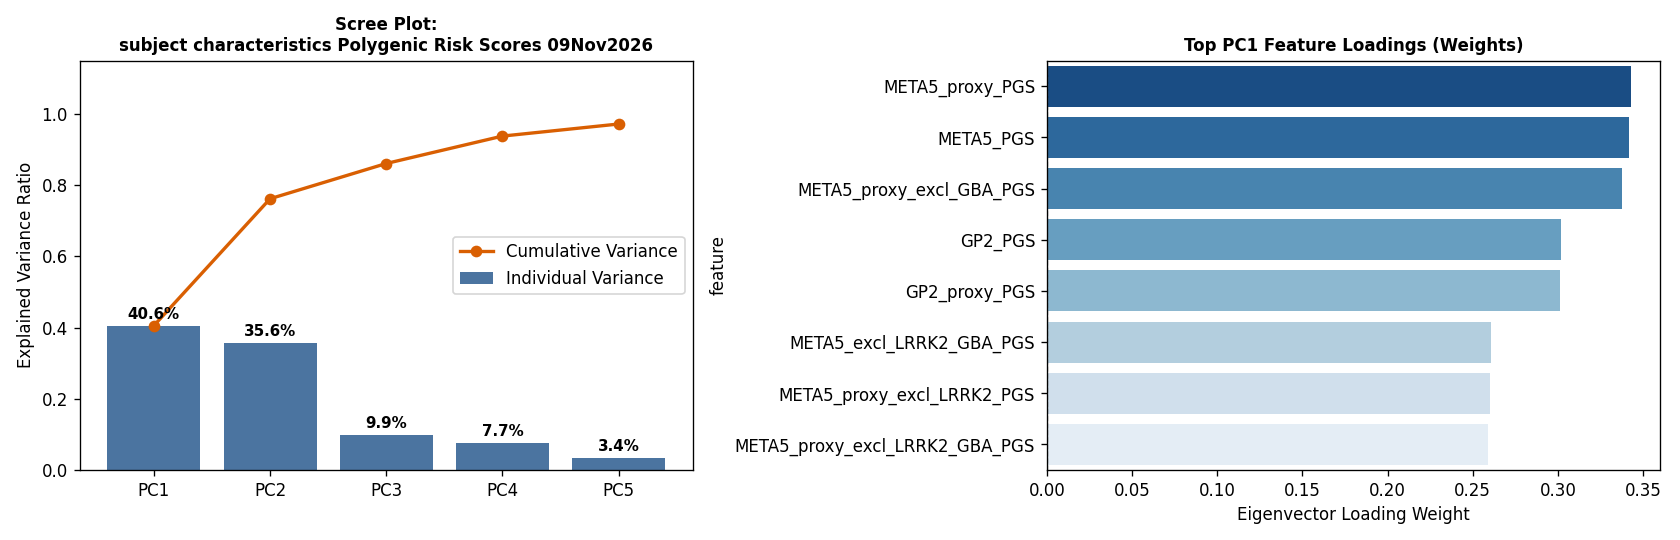

Privacy-Safe Shared-Space Side-by-Side Hexbin Score Density Plot (Cells < 5 Suppressed):


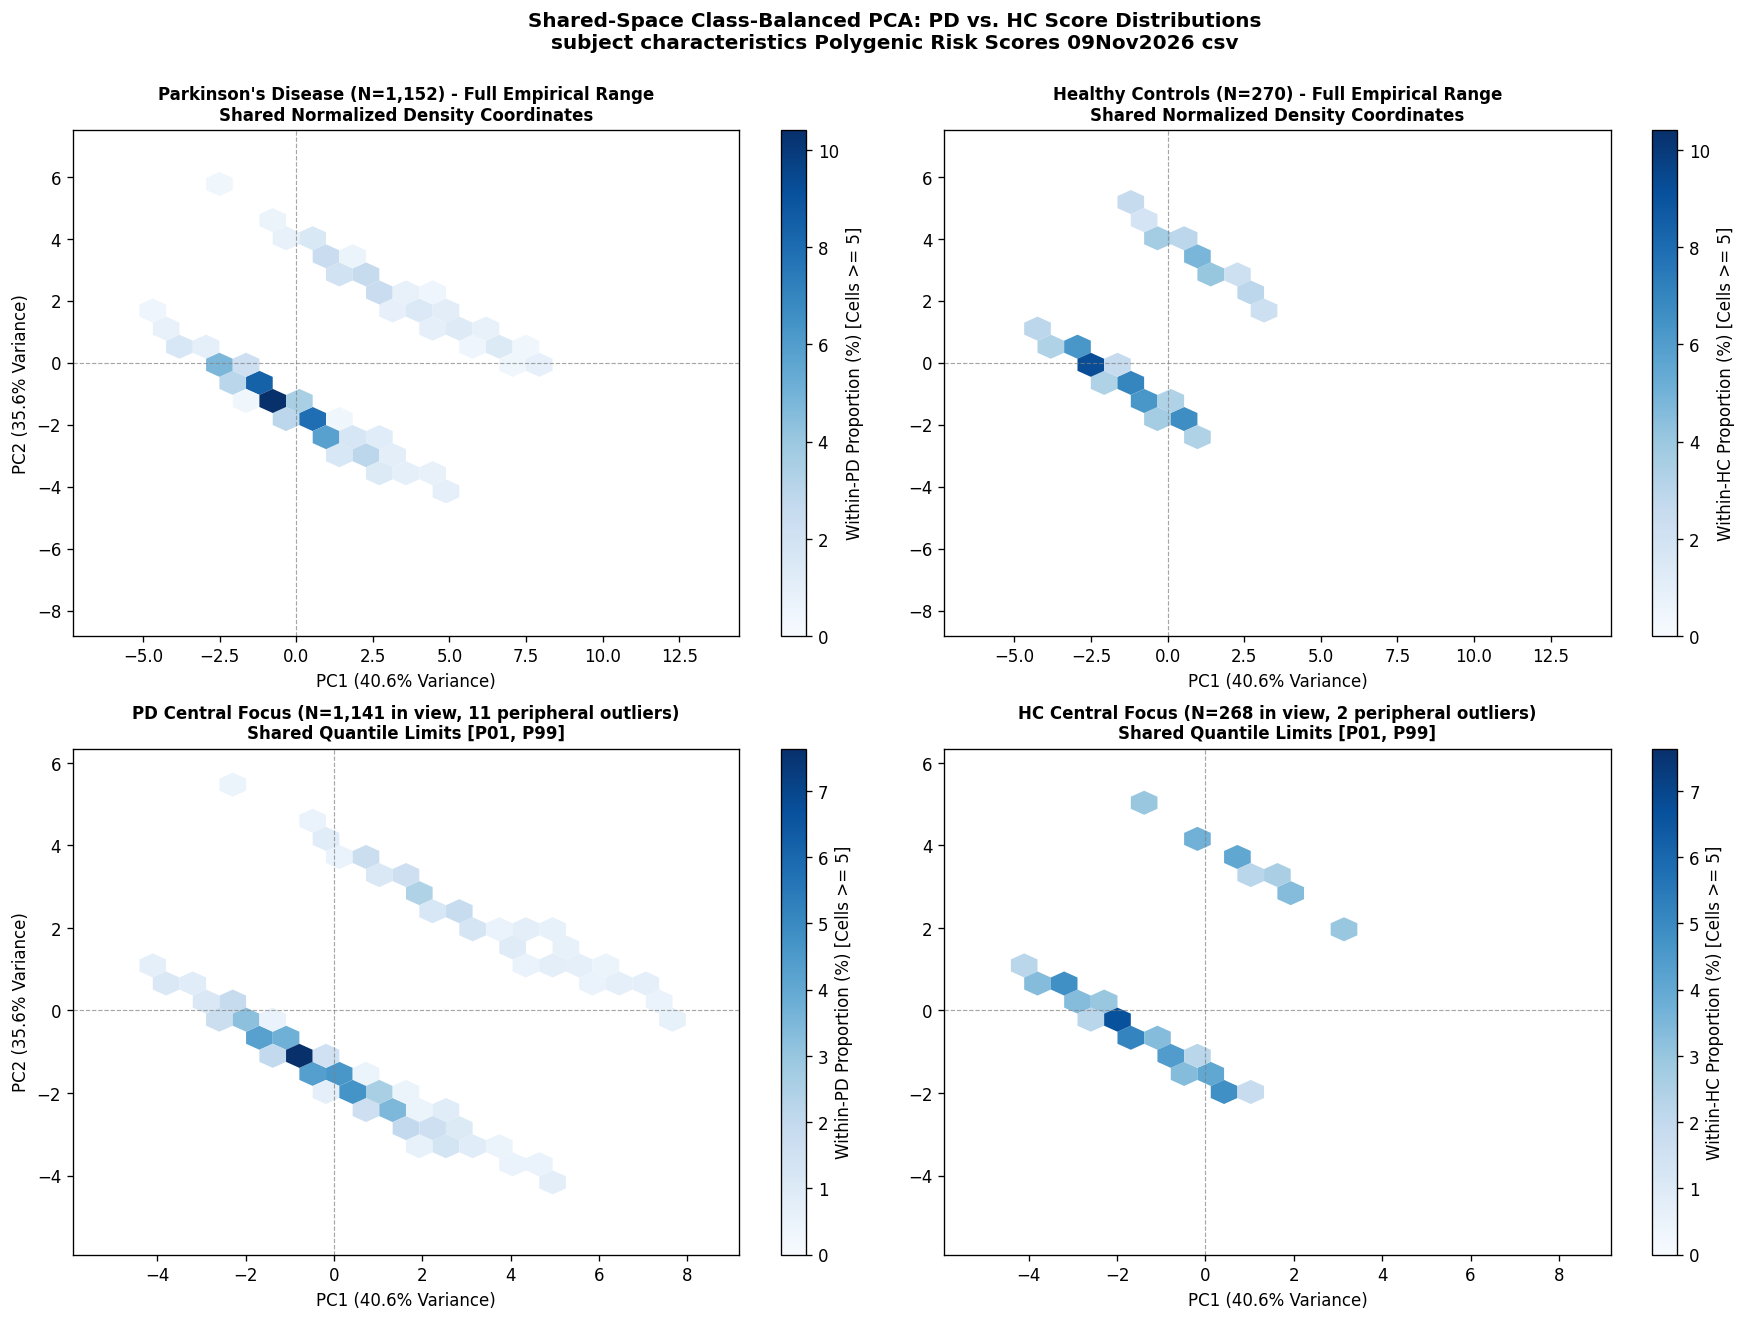

In [6]:
pca_res = unit_data["pca_results"]
c_denom = pca_res.get("class_denominators", {})

print("Shared-Space PCA Class Denominators:")
print(f"  - Initial Eligible PD: {c_denom.get('pd_initial_participants', 0):,} participants")
print(f"  - Initial Eligible HC: {c_denom.get('hc_initial_participants', 0):,} participants")
print(f"  - Class-Balanced Fit Size: {c_denom.get('balanced_fit_size_per_class', 0):,} participants per class (Total Fit N={c_denom.get('total_balanced_fit_observations', 0):,})")
print(f"  - Total Projected Participants: {c_denom.get('total_projected_participants', 0):,}")

# Explained Variance Table
exp_var = pca_res["explained_variance_ratio"]
cum_var = pca_res["cumulative_variance_ratio"]
var_df = pd.DataFrame({
    "Component": [f"PC{i+1}" for i in range(len(exp_var))],
    "Individual Variance Ratio": [f"{v:.2%}" for v in exp_var],
    "Cumulative Variance Ratio": [f"{v:.2%}" for v in cum_var]
})
display(var_df)

# Top PC1 and PC2 Loadings
top_pc1 = pd.DataFrame(pca_res.get("top_loadings_pc1", []))
top_pc2 = pd.DataFrame(pca_res.get("top_loadings_pc2", []))
print("\nTop PC1 Feature Loadings:")
display(top_pc1)

# Display Embedded Figures (Portable Relative Paths)
scree_rel = pca_res.get("scree_plot_path") or "EDA/outputs/reports/figures/scree_loadings/subject_characteristics_Polygenic_Risk_Scores_09Nov2026_csv_scree_loadings.png"
score_rel = pca_res.get("score_plot_path") or "EDA/outputs/reports/figures/pca_scores/subject_characteristics_Polygenic_Risk_Scores_09Nov2026_csv_pca_scores.png"
scree_path = repo_root / scree_rel if scree_rel else Path("NO_PATH")
score_path = repo_root / score_rel if score_rel else Path("NO_PATH")

if scree_path.exists():
    print("Scree & Eigenvector Loadings Plot:")
    display(Image(filename=str(scree_path)))

if score_path.exists():
    print("Privacy-Safe Shared-Space Side-by-Side Hexbin Score Density Plot (Cells < 5 Suppressed):")
    display(Image(filename=str(score_path)))

---
## 2.3. Unit: `Family_History_09Nov2026.csv` 
- **Unit Slug**: `subject_characteristics_Family_History_09Nov2026_csv`
- **Source Path**: `subject_characteristics/Family_History_09Nov2026.csv`
- **Committed Unit Artifact**: [`subject_characteristics_Family_History_09Nov2026_csv.json`](../EDA/outputs/reports/units/subject_characteristics_Family_History_09Nov2026_csv.json)
- **Declared Observation Grain**: `(PATNO, RELATIVE_TYPE)`
- **Selection Tier**: `Supporting` | **Role**: `Detailed pedigree survey documenting first-, second-, and third-degree biological relatives diagnosed with PD, tremor, or dementia.`
- **Terminal Statuses**: EDA: `COMPLETED` | PCA: `SKIPPED`

UNIT ANALYSIS: subject_characteristics/Family_History_09Nov2026.csv
EDA Status: COMPLETED | PCA Status: SKIPPED
Dimensions: 2,571 analyzed rows x 44 columns
Observation Grain: Participant-by-event repeated clinical observation (PATNO, EVENT_ID)
Candidate Primary Keys: [['REC_ID'], ['PATNO', 'EVENT_ID']]

Target Cohort Filtering Denominators:
  - Initial Rows: 9,310 (8,379 participants)
  - PD Retained:  2,127 rows (1,684 participants)
  - HC Retained:  444 rows (336 participants)
  - Non-Target Excluded: 3,373 rows (SWEDD/Prodromal)
  - Unmatched Excluded:  3,366 rows

Exact Variable Schema & Storage Types (44 columns):
Showing first 20 of 44 columns (complete schema committed to subject_characteristics_Family_History_09Nov2026_csv.json):


,name,dtype,missing_count,missing_percent,distinct_count,variable_role
0,REC_ID,object,0,0.0%,"2,571",Identifier
1,PATNO,int64,0,0.0%,"2,020",Identifier
2,EVENT_ID,object,0,0.0%,6,Identifier
3,PAG_NAME,object,0,0.0%,1,Administrative Metadata
4,INFODT,object,296,11.5%,115,Date / Timestamp / Visit
5,ANYFAMPD,float64,644,25.1%,2,Analytical Numeric Measurement
6,BIOMOM,int64,0,0.0%,1,Analytical Numeric Measurement
7,BIOMOMPD,float64,"1,109",43.1%,2,Analytical Numeric Measurement
8,BIODAD,float64,0,0.0%,1,Analytical Numeric Measurement
9,BIODADPD,float64,"1,110",43.2%,2,Analytical Numeric Measurement



Variable Role Distribution Summary:


,Count
variable_role,
Analytical Numeric Measurement,34
Identifier,5
Administrative Metadata,2
Date / Timestamp / Visit,2
Cohort / Stratification Label,1



Missingness & Duplicate Quality Evidence:
  - Total Missing Cells: 40,203 / 113,124 (35.54%)
  - Duplicate Rows Count: 0
  - Columns with Missing Values (33 total, top 8):


,name,missing_count,missing_percent,variable_role
40,PATCOUSPD,"2,047",79.6%,Analytical Numeric Measurement
38,MATCOUSPD,"2,047",79.6%,Analytical Numeric Measurement
21,PAHAFSIBPD,"2,046",79.6%,Analytical Numeric Measurement
20,MAHAFSIBPD,"2,044",79.5%,Analytical Numeric Measurement
14,FULBROPD,"2,043",79.5%,Analytical Numeric Measurement
15,FULSISPD,"2,041",79.4%,Analytical Numeric Measurement
29,PAGMOTHPD,"2,039",79.3%,Analytical Numeric Measurement
28,PAGFATHPD,"2,039",79.3%,Analytical Numeric Measurement



Categorical Variable Frequency Distributions (1 variables profiled):
  * Feature: TARGET_COHORT_STRATIFICATION (Distinct Categories: 2)


,category,row_count
0,PD,"2,127"
1,HC,444



Numeric Summaries & Outlier Diagnostics (34 continuous/discrete features):
Showing top 10 of 34 features (full distribution profiles in subject_characteristics_Family_History_09Nov2026_csv.json):


,variable,mean,std,min,median,max,skewness,shape,iqr_outliers_count,zscore_outliers_count
0,ANYFAMPD,0.428,0.495,0.0,0.0,1.0,0.291,Approximately symmetric,0,0
1,BIOMOM,1.000,0.000,1.0,1.0,1.0,0.000,Approximately symmetric,0,0
2,BIOMOMPD,0.129,0.335,0.0,0.0,1.0,2.221,Strongly skewed (positive),188,0
3,BIODAD,1.000,0.000,1.0,1.0,1.0,0.000,Approximately symmetric,0,0
4,BIODADPD,0.150,0.357,0.0,0.0,1.0,1.964,Strongly skewed (positive),219,0
5,FULSIB,2.290,1.853,0.0,2.0,22.0,1.888,Strongly skewed (positive),92,49
6,FULBRO,1.146,1.193,0.0,1.0,7.0,1.391,Strongly skewed (positive),12,30
7,FULSIS,1.153,1.286,0.0,1.0,20.0,3.220,Strongly skewed (positive),11,11
8,FULSIBPD,0.127,0.390,0.0,0.0,3.0,3.514,Strongly skewed (positive),152,21
9,FULBROPD,0.108,0.323,0.0,0.0,2.0,2.869,Strongly skewed (positive),55,2


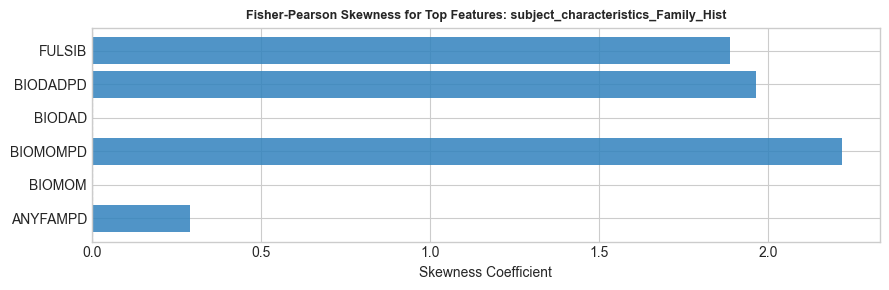

In [7]:
# Load committed unit artifact
unit_json_path = repo_root / "EDA" / "outputs" / "reports" / "units" / "subject_characteristics_Family_History_09Nov2026_csv.json"
with open(unit_json_path, "r", encoding="utf-8") as f:
    unit_data = json.load(f)

print("=" * 80)
print(f"UNIT ANALYSIS: subject_characteristics/Family_History_09Nov2026.csv")
print("=" * 80)
print(f"EDA Status: {unit_data['eda_status']} | PCA Status: {unit_data['pca_status']}")

if unit_data.get("eda_status") == "UNREADABLE":
    print(f"UNREADABLE EVIDENCE: {unit_data.get('eda_unreadable_evidence')}")
else:
    eda = unit_data["eda_diagnostics"]
    print(f"Dimensions: {eda['row_count']:,} analyzed rows x {eda['column_count']} columns")
    print(f"Observation Grain: {eda['observation_grain']}")
    print(f"Candidate Primary Keys: {eda.get('candidate_primary_keys', [])}")

    # Cohort Denominator Evidence
    cohort_ev = eda.get("cohort_filter_evidence")
    if cohort_ev and cohort_ev.get("has_participant_data"):
        print("\nTarget Cohort Filtering Denominators:")
        print(f"  - Initial Rows: {cohort_ev.get('total_rows_pre_filter', 0):,} ({cohort_ev.get('distinct_participants_pre_filter', 0):,} participants)")
        print(f"  - PD Retained:  {cohort_ev.get('pd_rows_retained', 0):,} rows ({cohort_ev.get('pd_participants_retained', 0):,} participants)")
        print(f"  - HC Retained:  {cohort_ev.get('hc_rows_retained', 0):,} rows ({cohort_ev.get('hc_participants_retained', 0):,} participants)")
        print(f"  - Non-Target Excluded: {cohort_ev.get('nontarget_rows_excluded', 0):,} rows (SWEDD/Prodromal)")
        print(f"  - Unmatched Excluded:  {cohort_ev.get('unmatched_rows_excluded', 0):,} rows")

    # 1. Exact Column Schema & Types Table
    cols_df = pd.DataFrame(eda["column_profiles"])
    role_col = "variable_role" if "variable_role" in cols_df.columns else "role"
    schema_cols = [c for c in ["name", "dtype", "missing_count", "missing_percent", "distinct_count", role_col] if c in cols_df.columns]
    schema_view = cols_df[schema_cols].copy()
    if "missing_count" in schema_view.columns:
        schema_view["missing_count"] = schema_view["missing_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "distinct_count" in schema_view.columns:
        schema_view["distinct_count"] = schema_view["distinct_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "missing_percent" in schema_view.columns:
        schema_view["missing_percent"] = schema_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v) if pd.notna(v) else "-")

    print(f"\nExact Variable Schema & Storage Types ({len(cols_df)} columns):")
    if len(schema_view) <= 25:
        display(schema_view)
    else:
        print(f"Showing first 20 of {len(schema_view)} columns (complete schema committed to subject_characteristics_Family_History_09Nov2026_csv.json):")
        display(schema_view.head(20))

    print("\nVariable Role Distribution Summary:")
    display(cols_df[role_col].value_counts().to_frame("Count"))

    # 2. Missingness and Duplicate Quality Evidence
    print(f"\nMissingness & Duplicate Quality Evidence:")
    print(f"  - Total Missing Cells: {eda['total_missing_cells']:,} / {eda['row_count']*eda['column_count']:,} ({eda['overall_missing_percent']:.2f}%)")
    print(f"  - Duplicate Rows Count: {eda['duplicate_rows_count']}")
    high_missing = cols_df[cols_df["missing_percent"] > 0].sort_values("missing_percent", ascending=False)
    if not high_missing.empty:
        print(f"  - Columns with Missing Values ({len(high_missing)} total, top 8):")
        missing_view = high_missing[["name", "missing_count", "missing_percent", role_col]].head(8).copy()
        missing_view["missing_count"] = missing_view["missing_count"].apply(lambda v: "{:,}".format(int(v)))
        missing_view["missing_percent"] = missing_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v))
        display(missing_view)
    else:
        print("  - Zero missing values detected across all columns.")

    # 3. Categorical Variable Frequency Summaries (<5 Suppressed)
    cat_summaries = eda.get("categorical_summaries", [])
    if cat_summaries:
        print(f"\nCategorical Variable Frequency Distributions ({len(cat_summaries)} variables profiled):")
        for cat_item in cat_summaries[:3]:
            var_name = cat_item.get("variable")
            freq_df = pd.DataFrame(cat_item.get("frequencies", []))
            print(f"  * Feature: {var_name} (Distinct Categories: {cat_item.get('distinct_count')})")
            if not freq_df.empty:
                freq_view = freq_df.copy()
                if "category" in freq_view.columns:
                    freq_view["category"] = freq_view["category"].apply(lambda c: "'" + str(c) + "'" if str(c).strip().upper() in ["ID", "PATNO", "SUBJID", "SUBJECT", "PARTICIPANT", "RECORD", "SAMPLE", "CASE", "PID", "RID"] else str(c))
                if "row_count" in freq_view.columns:
                    freq_view["row_count"] = freq_view["row_count"].apply(lambda v: "{:,}".format(int(v)) if isinstance(v, (int, float)) and pd.notna(v) else str(v))
                display(freq_view)
    else:
        print("\nCategorical Frequency Summaries: No multi-level categorical features for this unit.")

    # 4. Outlier and Numeric Summaries (Fisher-Pearson Skewness & Tukey IQR / Z-Score Diagnostics)
    if eda.get("numeric_summaries"):
        num_df = pd.DataFrame(eda["numeric_summaries"])
        print(f"\nNumeric Summaries & Outlier Diagnostics ({len(num_df)} continuous/discrete features):")
        var_col = "variable" if "variable" in num_df.columns else "name"
        cols_to_show = [c for c in [var_col, "mean", "std", "min", "median", "max", "skewness", "shape", "iqr_outliers_count", "zscore_outliers_count"] if c in num_df.columns]
        num_view = num_df[cols_to_show].copy()
        for count_col in ["iqr_outliers_count", "zscore_outliers_count"]:
            if count_col in num_view.columns:
                num_view[count_col] = num_view[count_col].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
        if len(num_view) <= 12:
            display(num_view)
        else:
            print(f"Showing top 10 of {len(num_view)} features (full distribution profiles in subject_characteristics_Family_History_09Nov2026_csv.json):")
            display(num_view.head(10))

    # 5. Exploratory Data Visualization
    if eda.get("numeric_summaries") and len(eda["numeric_summaries"]) >= 2:
        top_num = pd.DataFrame(eda["numeric_summaries"]).head(6)
        var_col = "variable" if "variable" in top_num.columns else "name"
        fig, ax = plt.subplots(figsize=(9, 3.0))
        ax.barh(top_num[var_col], top_num["skewness"], color="#3182bd", alpha=0.85)
        ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
        ax.set_title(f"Fisher-Pearson Skewness for Top Features: subject_characteristics_Family_Hist", fontsize=9, fontweight="bold")
        ax.set_xlabel("Skewness Coefficient")
        plt.tight_layout()
        plt.show()
    elif cat_summaries and cat_summaries[0].get("frequencies"):
        first_cat = cat_summaries[0]
        cat_freq_df = pd.DataFrame(first_cat["frequencies"])
        valid_freqs = cat_freq_df[cat_freq_df["row_count"] != "<5 (Suppressed)"].copy()
        if not valid_freqs.empty and len(valid_freqs) >= 2:
            fig, ax = plt.subplots(figsize=(8, 2.5))
            ax.barh(valid_freqs["category"].astype(str), pd.to_numeric(valid_freqs["row_count"]), color="#31a354", alpha=0.85)
            ax.set_title(f"Categorical Frequencies: {first_cat['variable']}", fontsize=9, fontweight="bold")
            ax.set_xlabel("Participant Row Count")
            plt.tight_layout()
            plt.show()

### Principal Component Analysis: Deterministic Skip
- **Status**: `SKIPPED`
- **Deterministic Skip Reason**: `Insufficient usable numeric analytical features (0 < 2)`
- **Methodological Justification**: This dataset does not meet the scientific prerequisites for multivariate PCA (e.g. lacks $\ge 2$ continuous analytical measurements, is an unpivoted single-measurement log, represents cell repository inventory, or lacks adequate two-class participant coverage).

In [8]:
pca_res = unit_data.get("pca_results") or {}
skip_reason = pca_res.get("skip_reason") or unit_data.get("pca_skip_reason")
print(f"PCA Skip Reason: {skip_reason}")
print(f"Features Evaluated: {pca_res.get('feature_count', 0)} included, {pca_res.get('excluded_features_count', 0)} excluded")
if pca_res.get("excluded_features"):
    ex_df = pd.DataFrame(pca_res["excluded_features"][:10])
    print("\nExcluded Variables Sample:")
    display(ex_df)

PCA Skip Reason: Insufficient usable numeric analytical features (0 < 2)
Features Evaluated: 0 included, 44 excluded

Excluded Variables Sample:


,feature_name,reason
0,REC_ID,Family pedigree structure; sibling/relative co...
1,PATNO,Family pedigree structure; sibling/relative co...
2,EVENT_ID,Family pedigree structure; sibling/relative co...
3,PAG_NAME,Family pedigree structure; sibling/relative co...
4,INFODT,Family pedigree structure; sibling/relative co...
5,ANYFAMPD,Family pedigree structure; sibling/relative co...
6,BIOMOM,Family pedigree structure; sibling/relative co...
7,BIOMOMPD,Family pedigree structure; sibling/relative co...
8,BIODAD,Family pedigree structure; sibling/relative co...
9,BIODADPD,Family pedigree structure; sibling/relative co...


---
## 2.4. Unit: `Genotypes_for_Polygenic_Risk_Scores_09Nov2026.csv` 
- **Unit Slug**: `subject_characteristics_Genotypes_for_Polygenic_Risk_Scores_09Nov2026_csv`
- **Source Path**: `subject_characteristics/Genotypes_for_Polygenic_Risk_Scores_09Nov2026.csv`
- **Committed Unit Artifact**: [`subject_characteristics_Genotypes_for_Polygenic_Risk_Scores_09Nov2026_csv.json`](../EDA/outputs/reports/units/subject_characteristics_Genotypes_for_Polygenic_Risk_Scores_09Nov2026_csv.json)
- **Declared Observation Grain**: `(PATNO, SNP_ID)`
- **Selection Tier**: `Supporting` | **Role**: `Measured dosage ($0, 1, 2$) and genotype calls across 240 genome-wide association risk loci used to construct polygenic scores.`
- **Terminal Statuses**: EDA: `COMPLETED` | PCA: `SKIPPED`

UNIT ANALYSIS: subject_characteristics/Genotypes_for_Polygenic_Risk_Scores_09Nov2026.csv
EDA Status: COMPLETED | PCA Status: SKIPPED
Dimensions: 135,840 analyzed rows x 10 columns
Observation Grain: Multiple repeated observations per participant (PATNO)
Candidate Primary Keys: []

Target Cohort Filtering Denominators:
  - Initial Rows: 214,560 (894 participants)
  - PD Retained:  95,520 rows (398 participants)
  - HC Retained:  40,320 rows (168 participants)
  - Non-Target Excluded: 55,440 rows (SWEDD/Prodromal)
  - Unmatched Excluded:  23,280 rows

Exact Variable Schema & Storage Types (10 columns):


,name,dtype,missing_count,missing_percent,distinct_count,variable_role
0,PATNO,int64,0,0.0%,566,Identifier
1,CHROM,object,0,0.0%,21,Categorical / Text
2,POS,int64,0,0.0%,240,Analytical Numeric Measurement
3,ID,object,0,0.0%,240,Identifier
4,RSID,object,"4,528",3.3%,232,Identifier
5,REF,object,0,0.0%,18,Categorical / Text
6,ALT,object,0,0.0%,5,Categorical / Text
7,QUAL,int64,0,0.0%,231,Analytical Numeric Measurement
8,GT,object,0,0.0%,48,Categorical / Text
9,TARGET_COHORT_STRATIFICATION,object,0,0.0%,2,Cohort / Stratification Label



Variable Role Distribution Summary:


,Count
variable_role,
Categorical / Text,4
Identifier,3
Analytical Numeric Measurement,2
Cohort / Stratification Label,1



Missingness & Duplicate Quality Evidence:
  - Total Missing Cells: 4,528 / 1,358,400 (0.33%)
  - Duplicate Rows Count: 0
  - Columns with Missing Values (1 total, top 8):


,name,missing_count,missing_percent,variable_role
4,RSID,"4,528",3.3%,Identifier


... (4 outputs left out)

  * Feature: ALT (Distinct Categories: 5)


,category,row_count
0,A,"36,224"
1,C,"33,394"
2,T,"33,394"
3,G,"32,262"
4,TAGAG,566



Numeric Summaries & Outlier Diagnostics (2 continuous/discrete features):


,variable,mean,std,min,median,max,skewness,shape,iqr_outliers_count,zscore_outliers_count
0,POS,7.744321e+07,5.909901e+07,906303.0,61189102.0,243578639.0,0.720,Moderately skewed (positive),0,0
1,QUAL,2.135267e+03,6.790450e+02,54.0,2188.0,4283.0,-0.347,Approximately symmetric,"2,264","1,698"


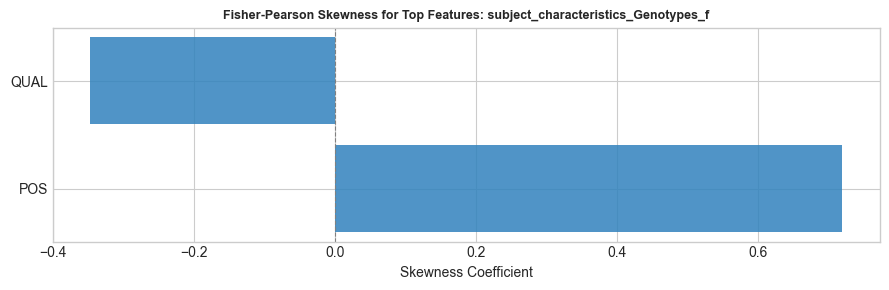

In [9]:
# Load committed unit artifact
unit_json_path = repo_root / "EDA" / "outputs" / "reports" / "units" / "subject_characteristics_Genotypes_for_Polygenic_Risk_Scores_09Nov2026_csv.json"
with open(unit_json_path, "r", encoding="utf-8") as f:
    unit_data = json.load(f)

print("=" * 80)
print(f"UNIT ANALYSIS: subject_characteristics/Genotypes_for_Polygenic_Risk_Scores_09Nov2026.csv")
print("=" * 80)
print(f"EDA Status: {unit_data['eda_status']} | PCA Status: {unit_data['pca_status']}")

if unit_data.get("eda_status") == "UNREADABLE":
    print(f"UNREADABLE EVIDENCE: {unit_data.get('eda_unreadable_evidence')}")
else:
    eda = unit_data["eda_diagnostics"]
    print(f"Dimensions: {eda['row_count']:,} analyzed rows x {eda['column_count']} columns")
    print(f"Observation Grain: {eda['observation_grain']}")
    print(f"Candidate Primary Keys: {eda.get('candidate_primary_keys', [])}")

    # Cohort Denominator Evidence
    cohort_ev = eda.get("cohort_filter_evidence")
    if cohort_ev and cohort_ev.get("has_participant_data"):
        print("\nTarget Cohort Filtering Denominators:")
        print(f"  - Initial Rows: {cohort_ev.get('total_rows_pre_filter', 0):,} ({cohort_ev.get('distinct_participants_pre_filter', 0):,} participants)")
        print(f"  - PD Retained:  {cohort_ev.get('pd_rows_retained', 0):,} rows ({cohort_ev.get('pd_participants_retained', 0):,} participants)")
        print(f"  - HC Retained:  {cohort_ev.get('hc_rows_retained', 0):,} rows ({cohort_ev.get('hc_participants_retained', 0):,} participants)")
        print(f"  - Non-Target Excluded: {cohort_ev.get('nontarget_rows_excluded', 0):,} rows (SWEDD/Prodromal)")
        print(f"  - Unmatched Excluded:  {cohort_ev.get('unmatched_rows_excluded', 0):,} rows")

    # 1. Exact Column Schema & Types Table
    cols_df = pd.DataFrame(eda["column_profiles"])
    role_col = "variable_role" if "variable_role" in cols_df.columns else "role"
    schema_cols = [c for c in ["name", "dtype", "missing_count", "missing_percent", "distinct_count", role_col] if c in cols_df.columns]
    schema_view = cols_df[schema_cols].copy()
    if "missing_count" in schema_view.columns:
        schema_view["missing_count"] = schema_view["missing_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "distinct_count" in schema_view.columns:
        schema_view["distinct_count"] = schema_view["distinct_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "missing_percent" in schema_view.columns:
        schema_view["missing_percent"] = schema_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v) if pd.notna(v) else "-")

    print(f"\nExact Variable Schema & Storage Types ({len(cols_df)} columns):")
    if len(schema_view) <= 25:
        display(schema_view)
    else:
        print(f"Showing first 20 of {len(schema_view)} columns (complete schema committed to subject_characteristics_Genotypes_for_Polygenic_Risk_Scores_09Nov2026_csv.json):")
        display(schema_view.head(20))

    print("\nVariable Role Distribution Summary:")
    display(cols_df[role_col].value_counts().to_frame("Count"))

    # 2. Missingness and Duplicate Quality Evidence
    print(f"\nMissingness & Duplicate Quality Evidence:")
    print(f"  - Total Missing Cells: {eda['total_missing_cells']:,} / {eda['row_count']*eda['column_count']:,} ({eda['overall_missing_percent']:.2f}%)")
    print(f"  - Duplicate Rows Count: {eda['duplicate_rows_count']}")
    high_missing = cols_df[cols_df["missing_percent"] > 0].sort_values("missing_percent", ascending=False)
    if not high_missing.empty:
        print(f"  - Columns with Missing Values ({len(high_missing)} total, top 8):")
        missing_view = high_missing[["name", "missing_count", "missing_percent", role_col]].head(8).copy()
        missing_view["missing_count"] = missing_view["missing_count"].apply(lambda v: "{:,}".format(int(v)))
        missing_view["missing_percent"] = missing_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v))
        display(missing_view)
    else:
        print("  - Zero missing values detected across all columns.")

    # 3. Categorical Variable Frequency Summaries (<5 Suppressed)
    cat_summaries = eda.get("categorical_summaries", [])
    if cat_summaries:
        print(f"\nCategorical Variable Frequency Distributions ({len(cat_summaries)} variables profiled):")
        for cat_item in cat_summaries[:3]:
            var_name = cat_item.get("variable")
            freq_df = pd.DataFrame(cat_item.get("frequencies", []))
            print(f"  * Feature: {var_name} (Distinct Categories: {cat_item.get('distinct_count')})")
            if not freq_df.empty:
                freq_view = freq_df.copy()
                if "category" in freq_view.columns:
                    freq_view["category"] = freq_view["category"].apply(lambda c: "'" + str(c) + "'" if str(c).strip().upper() in ["ID", "PATNO", "SUBJID", "SUBJECT", "PARTICIPANT", "RECORD", "SAMPLE", "CASE", "PID", "RID"] else str(c))
                if "row_count" in freq_view.columns:
                    freq_view["row_count"] = freq_view["row_count"].apply(lambda v: "{:,}".format(int(v)) if isinstance(v, (int, float)) and pd.notna(v) else str(v))
                display(freq_view)
    else:
        print("\nCategorical Frequency Summaries: No multi-level categorical features for this unit.")

    # 4. Outlier and Numeric Summaries (Fisher-Pearson Skewness & Tukey IQR / Z-Score Diagnostics)
    if eda.get("numeric_summaries"):
        num_df = pd.DataFrame(eda["numeric_summaries"])
        print(f"\nNumeric Summaries & Outlier Diagnostics ({len(num_df)} continuous/discrete features):")
        var_col = "variable" if "variable" in num_df.columns else "name"
        cols_to_show = [c for c in [var_col, "mean", "std", "min", "median", "max", "skewness", "shape", "iqr_outliers_count", "zscore_outliers_count"] if c in num_df.columns]
        num_view = num_df[cols_to_show].copy()
        for count_col in ["iqr_outliers_count", "zscore_outliers_count"]:
            if count_col in num_view.columns:
                num_view[count_col] = num_view[count_col].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
        if len(num_view) <= 12:
            display(num_view)
        else:
            print(f"Showing top 10 of {len(num_view)} features (full distribution profiles in subject_characteristics_Genotypes_for_Polygenic_Risk_Scores_09Nov2026_csv.json):")
            display(num_view.head(10))

    # 5. Exploratory Data Visualization
    if eda.get("numeric_summaries") and len(eda["numeric_summaries"]) >= 2:
        top_num = pd.DataFrame(eda["numeric_summaries"]).head(6)
        var_col = "variable" if "variable" in top_num.columns else "name"
        fig, ax = plt.subplots(figsize=(9, 3.0))
        ax.barh(top_num[var_col], top_num["skewness"], color="#3182bd", alpha=0.85)
        ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
        ax.set_title(f"Fisher-Pearson Skewness for Top Features: subject_characteristics_Genotypes_f", fontsize=9, fontweight="bold")
        ax.set_xlabel("Skewness Coefficient")
        plt.tight_layout()
        plt.show()
    elif cat_summaries and cat_summaries[0].get("frequencies"):
        first_cat = cat_summaries[0]
        cat_freq_df = pd.DataFrame(first_cat["frequencies"])
        valid_freqs = cat_freq_df[cat_freq_df["row_count"] != "<5 (Suppressed)"].copy()
        if not valid_freqs.empty and len(valid_freqs) >= 2:
            fig, ax = plt.subplots(figsize=(8, 2.5))
            ax.barh(valid_freqs["category"].astype(str), pd.to_numeric(valid_freqs["row_count"]), color="#31a354", alpha=0.85)
            ax.set_title(f"Categorical Frequencies: {first_cat['variable']}", fontsize=9, fontweight="bold")
            ax.set_xlabel("Participant Row Count")
            plt.tight_layout()
            plt.show()

### Principal Component Analysis: Deterministic Skip
- **Status**: `SKIPPED`
- **Deterministic Skip Reason**: `Insufficient usable numeric analytical features (0 < 2)`
- **Methodological Justification**: This dataset does not meet the scientific prerequisites for multivariate PCA (e.g. lacks $\ge 2$ continuous analytical measurements, is an unpivoted single-measurement log, represents cell repository inventory, or lacks adequate two-class participant coverage).

In [10]:
pca_res = unit_data.get("pca_results") or {}
skip_reason = pca_res.get("skip_reason") or unit_data.get("pca_skip_reason")
print(f"PCA Skip Reason: {skip_reason}")
print(f"Features Evaluated: {pca_res.get('feature_count', 0)} included, {pca_res.get('excluded_features_count', 0)} excluded")
if pca_res.get("excluded_features"):
    ex_df = pd.DataFrame(pca_res["excluded_features"][:10])
    print("\nExcluded Variables Sample:")
    display(ex_df)

PCA Skip Reason: Insufficient usable numeric analytical features (0 < 2)
Features Evaluated: 0 included, 10 excluded

Excluded Variables Sample:


,feature_name,reason
0,PATNO,Tall variant-call format (VCF-like); single va...
1,CHROM,Tall variant-call format (VCF-like); single va...
2,POS,Tall variant-call format (VCF-like); single va...
3,ID,Tall variant-call format (VCF-like); single va...
4,RSID,Tall variant-call format (VCF-like); single va...
5,REF,Tall variant-call format (VCF-like); single va...
6,ALT,Tall variant-call format (VCF-like); single va...
7,QUAL,Tall variant-call format (VCF-like); single va...
8,GT,Tall variant-call format (VCF-like); single va...
9,TARGET_COHORT_STRATIFICATION,Tall variant-call format (VCF-like); single va...


---
## 2.5. Unit: `PPMI_Project_9001_20250624_09Nov2026.csv` 
- **Unit Slug**: `subject_characteristics_PPMI_Project_9001_20250624_09Nov2026_csv`
- **Source Path**: `subject_characteristics/PPMI_Project_9001_20250624_09Nov2026.csv`
- **Committed Unit Artifact**: [`subject_characteristics_PPMI_Project_9001_20250624_09Nov2026_csv.json`](../EDA/outputs/reports/units/subject_characteristics_PPMI_Project_9001_20250624_09Nov2026_csv.json)
- **Declared Observation Grain**: `(PATNO,)`
- **Selection Tier**: `Supporting` | **Role**: `Deep targeted resequencing of known Parkinson's loci across enriched genetic cohorts.`
- **Terminal Statuses**: EDA: `COMPLETED` | PCA: `COMPLETED`

UNIT ANALYSIS: subject_characteristics/PPMI_Project_9001_20250624_09Nov2026.csv
EDA Status: COMPLETED | PCA Status: COMPLETED
Dimensions: 797 analyzed rows x 110 columns
Observation Grain: Participant-by-event repeated clinical observation (PATNO, EVENT_ID)
Candidate Primary Keys: [['PATNO'], ['Genetic_PRS_PC2'], ['Genetic_PRS_PC3'], ['Genetic_PRS_PC4'], ['Genetic_PRS_PC5'], ['Genetic_PRS_PC6'], ['Genetic_PRS_PC7'], ['Genetic_PRS_PC9'], ['Genetic_PRS_PC10'], ['PATNO', 'EVENT_ID']]

Target Cohort Filtering Denominators:
  - Initial Rows: 1,319 (1,319 participants)
  - PD Retained:  603 rows (603 participants)
  - HC Retained:  194 rows (194 participants)
  - Non-Target Excluded: 446 rows (SWEDD/Prodromal)
  - Unmatched Excluded:  76 rows

Exact Variable Schema & Storage Types (110 columns):
Showing first 20 of 110 columns (complete schema committed to subject_characteristics_PPMI_Project_9001_20250624_09Nov2026_csv.json):


,name,dtype,missing_count,missing_percent,distinct_count,variable_role
0,PATNO,int64,0,0.0%,797,Identifier
1,EVENT_ID,object,0,0.0%,1,Identifier
2,Genetic_PRS_InfPop,object,0,0.0%,4,Categorical / Text
3,Genetic_PRS_PRS88,float64,0,0.0%,793,Analytical Numeric Measurement
4,Genetic_PRS_PRS83,float64,0,0.0%,783,Analytical Numeric Measurement
5,Genetic_PRS_PRSp90,float64,0,0.0%,788,Analytical Numeric Measurement
6,Genetic_PRS_PRSp88,float64,0,0.0%,780,Analytical Numeric Measurement
7,Genetic_PRS_PRSp87,float64,0,0.0%,784,Analytical Numeric Measurement
8,Genetic_PRS_PRSp85,float64,0,0.0%,776,Analytical Numeric Measurement
9,Genetic_PRS_PC1,float64,0,0.0%,796,Analytical Numeric Measurement



Variable Role Distribution Summary:


,Count
variable_role,
Analytical Numeric Measurement,106
Identifier,2
Categorical / Text,1
Cohort / Stratification Label,1



Missingness & Duplicate Quality Evidence:
  - Total Missing Cells: 0 / 87,670 (0.00%)
  - Duplicate Rows Count: 0
  - Zero missing values detected across all columns.

Categorical Variable Frequency Distributions (2 variables profiled):
  * Feature: Genetic_PRS_InfPop (Distinct Categories: 4)


,category,row_count
0,EUR,750
1,OTHER,26
2,AFR,14
3,EAS,7


  * Feature: TARGET_COHORT_STRATIFICATION (Distinct Categories: 2)


,category,row_count
0,PD,603
1,HC,194



Numeric Summaries & Outlier Diagnostics (106 continuous/discrete features):
Showing top 10 of 106 features (full distribution profiles in subject_characteristics_PPMI_Project_9001_20250624_09Nov2026_csv.json):


,variable,mean,std,min,median,max,skewness,shape,iqr_outliers_count,zscore_outliers_count
0,Genetic_PRS_PRS88,-0.139,0.947,-2.338,-0.321,3.816,0.935,Moderately skewed (positive),46,4
1,Genetic_PRS_PRS83,0.073,1.007,-3.312,0.108,2.612,-0.115,Approximately symmetric,3,1
2,Genetic_PRS_PRSp90,-0.135,0.949,-2.282,-0.309,3.768,0.938,Moderately skewed (positive),45,4
3,Genetic_PRS_PRSp88,-0.023,0.978,-3.037,-0.032,3.402,0.075,Approximately symmetric,3,3
4,Genetic_PRS_PRSp87,-0.079,0.940,-2.166,-0.264,3.931,1.099,Strongly skewed (positive),69,4
5,Genetic_PRS_PRSp85,0.080,1.006,-3.186,0.100,2.717,-0.099,Approximately symmetric,1,1
6,Genetic_PRS_PC1,-0.029,1.118,-0.647,-0.348,8.113,4.985,Strongly skewed (positive),41,23
7,Genetic_PRS_PC2,0.025,1.060,-4.062,-0.038,9.373,5.087,Strongly skewed (positive),52,23
8,Genetic_PRS_PC3,0.280,0.878,-1.896,0.726,1.433,-1.117,Strongly skewed (negative),0,0
9,Genetic_PRS_PC4,0.261,0.970,-2.639,0.563,9.772,1.728,Strongly skewed (positive),20,4


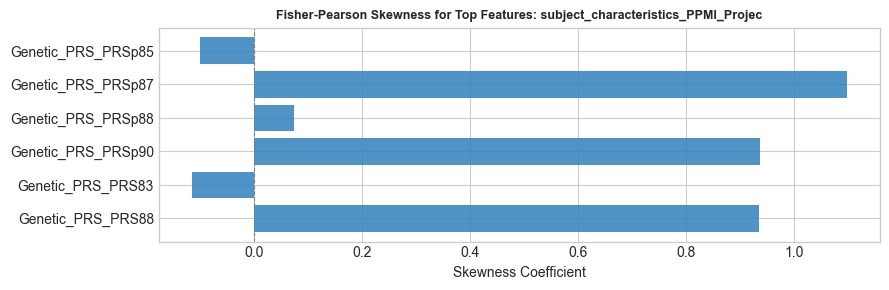

In [11]:
# Load committed unit artifact
unit_json_path = repo_root / "EDA" / "outputs" / "reports" / "units" / "subject_characteristics_PPMI_Project_9001_20250624_09Nov2026_csv.json"
with open(unit_json_path, "r", encoding="utf-8") as f:
    unit_data = json.load(f)

print("=" * 80)
print(f"UNIT ANALYSIS: subject_characteristics/PPMI_Project_9001_20250624_09Nov2026.csv")
print("=" * 80)
print(f"EDA Status: {unit_data['eda_status']} | PCA Status: {unit_data['pca_status']}")

if unit_data.get("eda_status") == "UNREADABLE":
    print(f"UNREADABLE EVIDENCE: {unit_data.get('eda_unreadable_evidence')}")
else:
    eda = unit_data["eda_diagnostics"]
    print(f"Dimensions: {eda['row_count']:,} analyzed rows x {eda['column_count']} columns")
    print(f"Observation Grain: {eda['observation_grain']}")
    print(f"Candidate Primary Keys: {eda.get('candidate_primary_keys', [])}")

    # Cohort Denominator Evidence
    cohort_ev = eda.get("cohort_filter_evidence")
    if cohort_ev and cohort_ev.get("has_participant_data"):
        print("\nTarget Cohort Filtering Denominators:")
        print(f"  - Initial Rows: {cohort_ev.get('total_rows_pre_filter', 0):,} ({cohort_ev.get('distinct_participants_pre_filter', 0):,} participants)")
        print(f"  - PD Retained:  {cohort_ev.get('pd_rows_retained', 0):,} rows ({cohort_ev.get('pd_participants_retained', 0):,} participants)")
        print(f"  - HC Retained:  {cohort_ev.get('hc_rows_retained', 0):,} rows ({cohort_ev.get('hc_participants_retained', 0):,} participants)")
        print(f"  - Non-Target Excluded: {cohort_ev.get('nontarget_rows_excluded', 0):,} rows (SWEDD/Prodromal)")
        print(f"  - Unmatched Excluded:  {cohort_ev.get('unmatched_rows_excluded', 0):,} rows")

    # 1. Exact Column Schema & Types Table
    cols_df = pd.DataFrame(eda["column_profiles"])
    role_col = "variable_role" if "variable_role" in cols_df.columns else "role"
    schema_cols = [c for c in ["name", "dtype", "missing_count", "missing_percent", "distinct_count", role_col] if c in cols_df.columns]
    schema_view = cols_df[schema_cols].copy()
    if "missing_count" in schema_view.columns:
        schema_view["missing_count"] = schema_view["missing_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "distinct_count" in schema_view.columns:
        schema_view["distinct_count"] = schema_view["distinct_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "missing_percent" in schema_view.columns:
        schema_view["missing_percent"] = schema_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v) if pd.notna(v) else "-")

    print(f"\nExact Variable Schema & Storage Types ({len(cols_df)} columns):")
    if len(schema_view) <= 25:
        display(schema_view)
    else:
        print(f"Showing first 20 of {len(schema_view)} columns (complete schema committed to subject_characteristics_PPMI_Project_9001_20250624_09Nov2026_csv.json):")
        display(schema_view.head(20))

    print("\nVariable Role Distribution Summary:")
    display(cols_df[role_col].value_counts().to_frame("Count"))

    # 2. Missingness and Duplicate Quality Evidence
    print(f"\nMissingness & Duplicate Quality Evidence:")
    print(f"  - Total Missing Cells: {eda['total_missing_cells']:,} / {eda['row_count']*eda['column_count']:,} ({eda['overall_missing_percent']:.2f}%)")
    print(f"  - Duplicate Rows Count: {eda['duplicate_rows_count']}")
    high_missing = cols_df[cols_df["missing_percent"] > 0].sort_values("missing_percent", ascending=False)
    if not high_missing.empty:
        print(f"  - Columns with Missing Values ({len(high_missing)} total, top 8):")
        missing_view = high_missing[["name", "missing_count", "missing_percent", role_col]].head(8).copy()
        missing_view["missing_count"] = missing_view["missing_count"].apply(lambda v: "{:,}".format(int(v)))
        missing_view["missing_percent"] = missing_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v))
        display(missing_view)
    else:
        print("  - Zero missing values detected across all columns.")

    # 3. Categorical Variable Frequency Summaries (<5 Suppressed)
    cat_summaries = eda.get("categorical_summaries", [])
    if cat_summaries:
        print(f"\nCategorical Variable Frequency Distributions ({len(cat_summaries)} variables profiled):")
        for cat_item in cat_summaries[:3]:
            var_name = cat_item.get("variable")
            freq_df = pd.DataFrame(cat_item.get("frequencies", []))
            print(f"  * Feature: {var_name} (Distinct Categories: {cat_item.get('distinct_count')})")
            if not freq_df.empty:
                freq_view = freq_df.copy()
                if "category" in freq_view.columns:
                    freq_view["category"] = freq_view["category"].apply(lambda c: "'" + str(c) + "'" if str(c).strip().upper() in ["ID", "PATNO", "SUBJID", "SUBJECT", "PARTICIPANT", "RECORD", "SAMPLE", "CASE", "PID", "RID"] else str(c))
                if "row_count" in freq_view.columns:
                    freq_view["row_count"] = freq_view["row_count"].apply(lambda v: "{:,}".format(int(v)) if isinstance(v, (int, float)) and pd.notna(v) else str(v))
                display(freq_view)
    else:
        print("\nCategorical Frequency Summaries: No multi-level categorical features for this unit.")

    # 4. Outlier and Numeric Summaries (Fisher-Pearson Skewness & Tukey IQR / Z-Score Diagnostics)
    if eda.get("numeric_summaries"):
        num_df = pd.DataFrame(eda["numeric_summaries"])
        print(f"\nNumeric Summaries & Outlier Diagnostics ({len(num_df)} continuous/discrete features):")
        var_col = "variable" if "variable" in num_df.columns else "name"
        cols_to_show = [c for c in [var_col, "mean", "std", "min", "median", "max", "skewness", "shape", "iqr_outliers_count", "zscore_outliers_count"] if c in num_df.columns]
        num_view = num_df[cols_to_show].copy()
        for count_col in ["iqr_outliers_count", "zscore_outliers_count"]:
            if count_col in num_view.columns:
                num_view[count_col] = num_view[count_col].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
        if len(num_view) <= 12:
            display(num_view)
        else:
            print(f"Showing top 10 of {len(num_view)} features (full distribution profiles in subject_characteristics_PPMI_Project_9001_20250624_09Nov2026_csv.json):")
            display(num_view.head(10))

    # 5. Exploratory Data Visualization
    if eda.get("numeric_summaries") and len(eda["numeric_summaries"]) >= 2:
        top_num = pd.DataFrame(eda["numeric_summaries"]).head(6)
        var_col = "variable" if "variable" in top_num.columns else "name"
        fig, ax = plt.subplots(figsize=(9, 3.0))
        ax.barh(top_num[var_col], top_num["skewness"], color="#3182bd", alpha=0.85)
        ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
        ax.set_title(f"Fisher-Pearson Skewness for Top Features: subject_characteristics_PPMI_Projec", fontsize=9, fontweight="bold")
        ax.set_xlabel("Skewness Coefficient")
        plt.tight_layout()
        plt.show()
    elif cat_summaries and cat_summaries[0].get("frequencies"):
        first_cat = cat_summaries[0]
        cat_freq_df = pd.DataFrame(first_cat["frequencies"])
        valid_freqs = cat_freq_df[cat_freq_df["row_count"] != "<5 (Suppressed)"].copy()
        if not valid_freqs.empty and len(valid_freqs) >= 2:
            fig, ax = plt.subplots(figsize=(8, 2.5))
            ax.barh(valid_freqs["category"].astype(str), pd.to_numeric(valid_freqs["row_count"]), color="#31a354", alpha=0.85)
            ax.set_title(f"Categorical Frequencies: {first_cat['variable']}", fontsize=9, fontweight="bold")
            ax.set_xlabel("Participant Row Count")
            plt.tight_layout()
            plt.show()

### Principal Component Analysis: Shared-Space Class-Balanced Projection
- **Model Architecture**: One record per participant, fit strictly on balanced sample ($k = \min(N_{PD}, N_{HC})$)
- **Features Retained**: `106` continuous analytical measurements
- **Excluded Features**: `4` variables (identifiers, versions, demographics, codes, staging)
- **Explained Variance**: PC1 explains `6.8%` of shared multivariate variance

Shared-Space PCA Class Denominators:
  - Initial Eligible PD: 603 participants
  - Initial Eligible HC: 194 participants
  - Class-Balanced Fit Size: 194 participants per class (Total Fit N=388)
  - Total Projected Participants: 797


,Component,Individual Variance Ratio,Cumulative Variance Ratio
0,PC1,6.77%,6.77%
1,PC2,3.39%,10.16%
2,PC3,2.44%,12.60%
3,PC4,2.15%,14.75%
4,PC5,2.00%,16.76%



Top PC1 Feature Loadings:


,feature_name,loading
0,Genetic_PRS_PRSp90,0.3422
1,Genetic_PRS_PRS88,0.3420
2,Genetic_PRS_PRSp87,0.3335
3,Genetic_PRS_PRS83,0.3272
4,Genetic_PRS_PRSp85,0.3246


Scree & Eigenvector Loadings Plot:


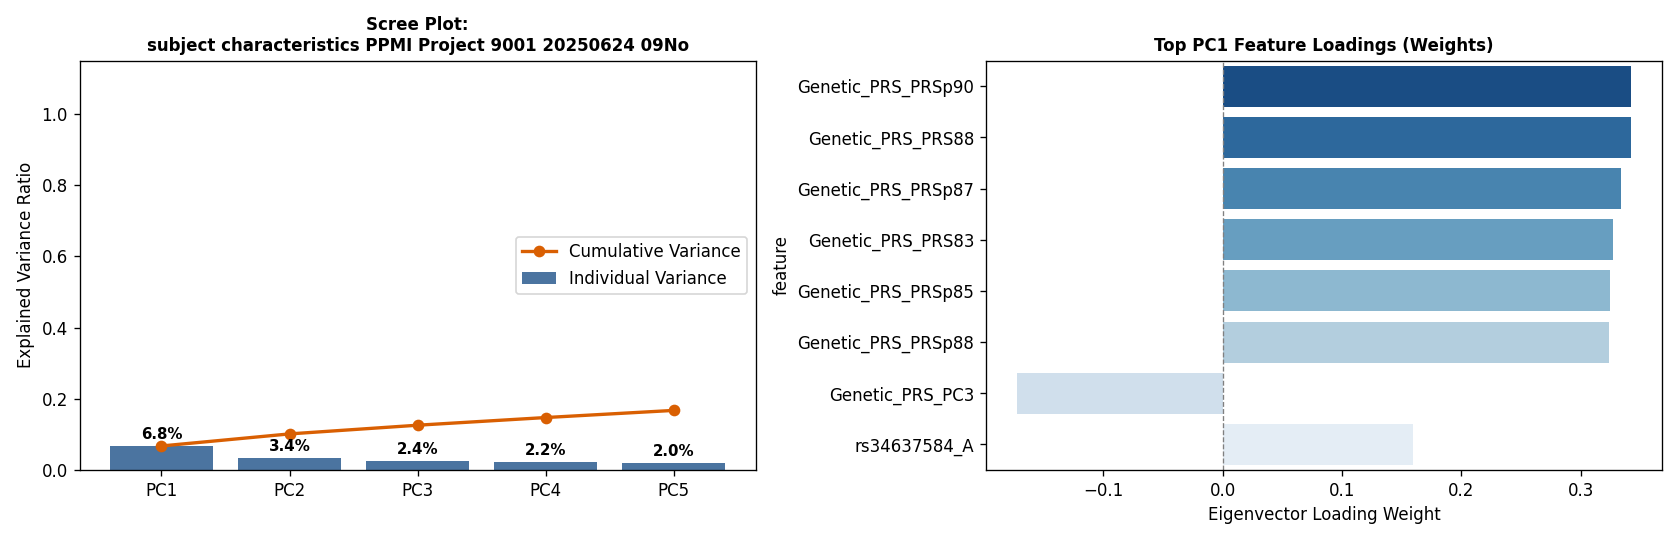

Privacy-Safe Shared-Space Side-by-Side Hexbin Score Density Plot (Cells < 5 Suppressed):


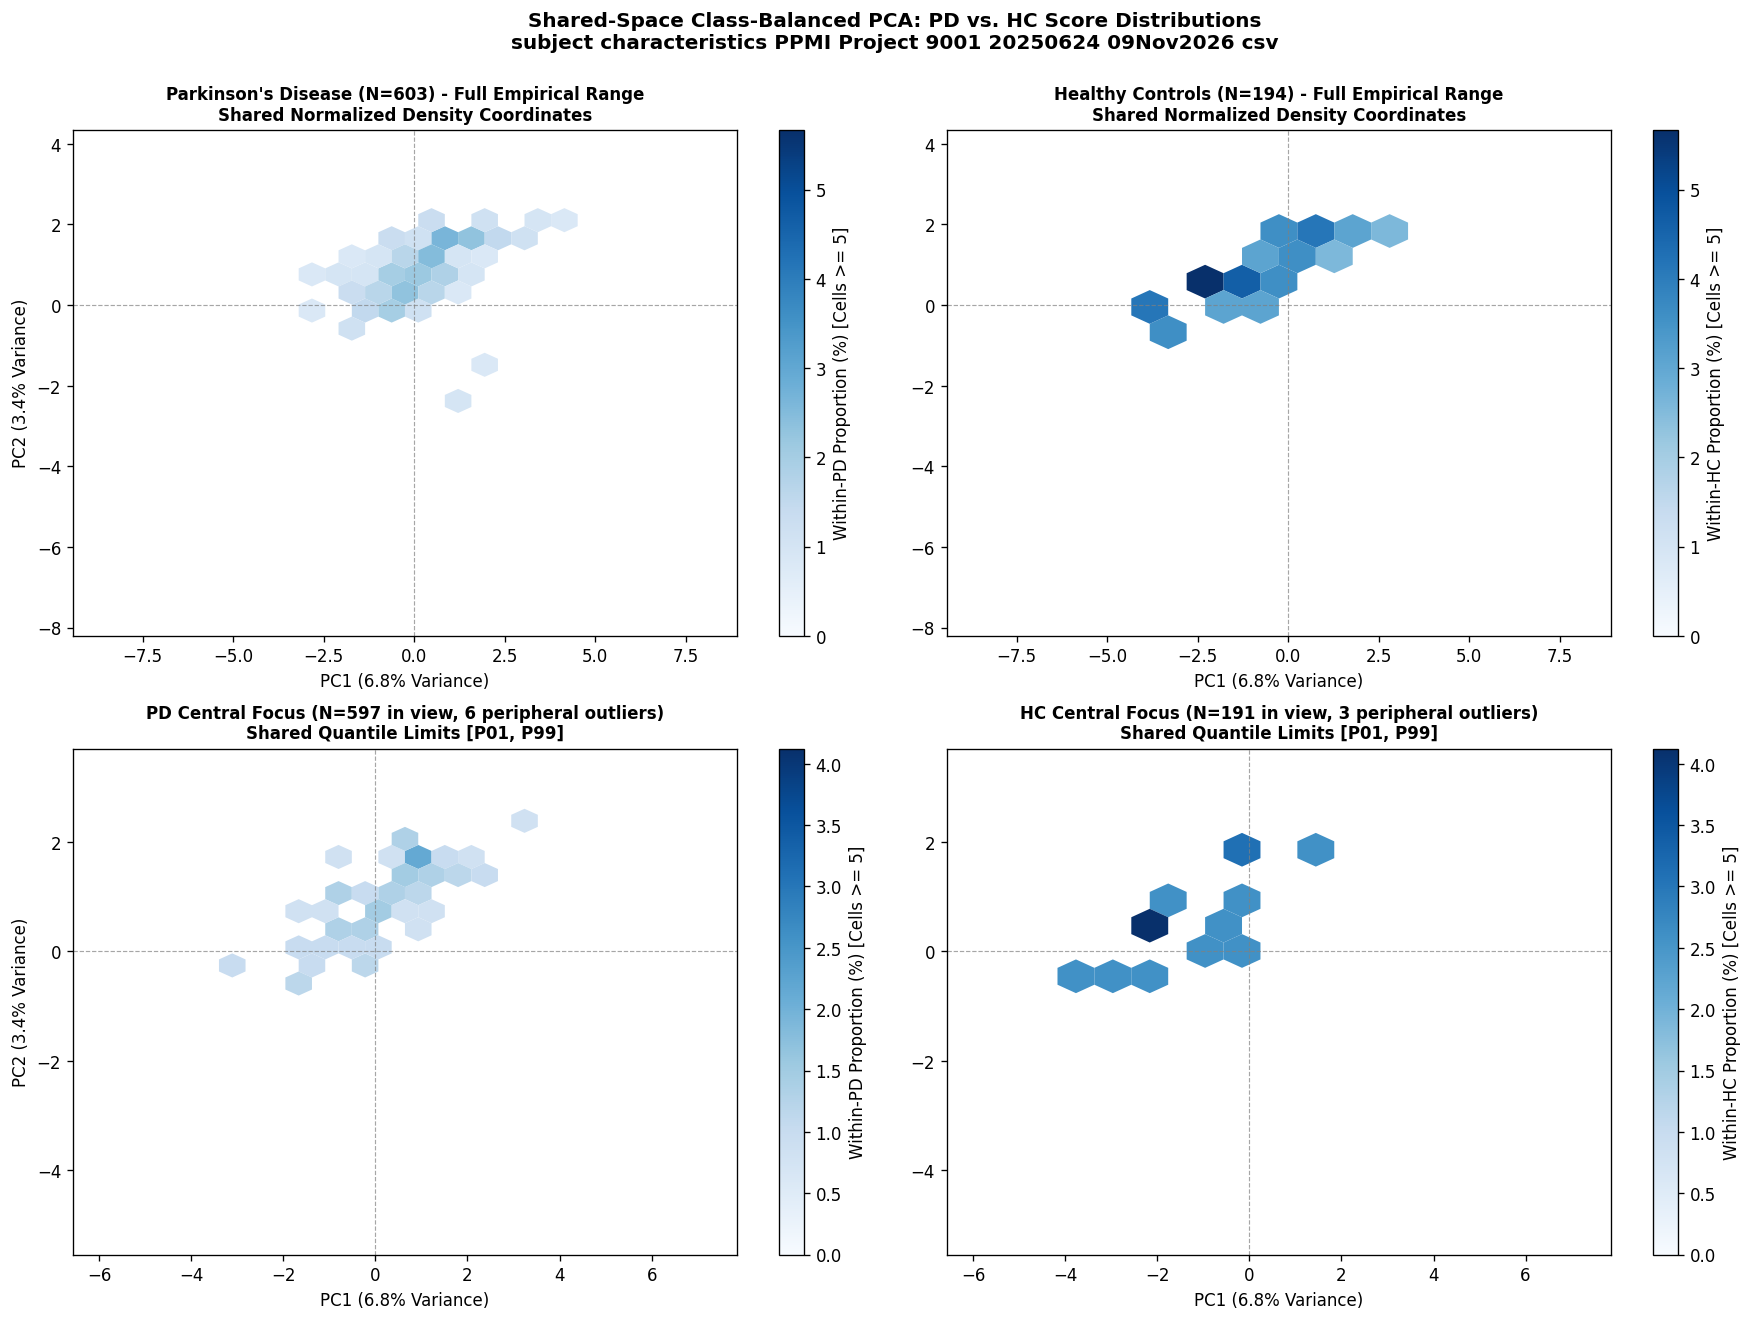

In [12]:
pca_res = unit_data["pca_results"]
c_denom = pca_res.get("class_denominators", {})

print("Shared-Space PCA Class Denominators:")
print(f"  - Initial Eligible PD: {c_denom.get('pd_initial_participants', 0):,} participants")
print(f"  - Initial Eligible HC: {c_denom.get('hc_initial_participants', 0):,} participants")
print(f"  - Class-Balanced Fit Size: {c_denom.get('balanced_fit_size_per_class', 0):,} participants per class (Total Fit N={c_denom.get('total_balanced_fit_observations', 0):,})")
print(f"  - Total Projected Participants: {c_denom.get('total_projected_participants', 0):,}")

# Explained Variance Table
exp_var = pca_res["explained_variance_ratio"]
cum_var = pca_res["cumulative_variance_ratio"]
var_df = pd.DataFrame({
    "Component": [f"PC{i+1}" for i in range(len(exp_var))],
    "Individual Variance Ratio": [f"{v:.2%}" for v in exp_var],
    "Cumulative Variance Ratio": [f"{v:.2%}" for v in cum_var]
})
display(var_df)

# Top PC1 and PC2 Loadings
top_pc1 = pd.DataFrame(pca_res.get("top_loadings_pc1", []))
top_pc2 = pd.DataFrame(pca_res.get("top_loadings_pc2", []))
print("\nTop PC1 Feature Loadings:")
display(top_pc1)

# Display Embedded Figures (Portable Relative Paths)
scree_rel = pca_res.get("scree_plot_path") or "EDA/outputs/reports/figures/scree_loadings/subject_characteristics_PPMI_Project_9001_20250624_09Nov2026_csv_scree_loadings.png"
score_rel = pca_res.get("score_plot_path") or "EDA/outputs/reports/figures/pca_scores/subject_characteristics_PPMI_Project_9001_20250624_09Nov2026_csv_pca_scores.png"
scree_path = repo_root / scree_rel if scree_rel else Path("NO_PATH")
score_path = repo_root / score_rel if score_rel else Path("NO_PATH")

if scree_path.exists():
    print("Scree & Eigenvector Loadings Plot:")
    display(Image(filename=str(scree_path)))

if score_path.exists():
    print("Privacy-Safe Shared-Space Side-by-Side Hexbin Score Density Plot (Cells < 5 Suppressed):")
    display(Image(filename=str(score_path)))

---
## 2.6. Unit: `PPMI_PD_Variants_Genetic_Status_WGS_20180921.csv` 
- **Unit Slug**: `subject_characteristics_PPMI_PD_Variants_Genetic_Status_WGS_20180921_csv`
- **Source Path**: `subject_characteristics/PPMI_PD_Variants_Genetic_Status_WGS_20180921.csv`
- **Committed Unit Artifact**: [`subject_characteristics_PPMI_PD_Variants_Genetic_Status_WGS_20180921_csv.json`](../EDA/outputs/reports/units/subject_characteristics_PPMI_PD_Variants_Genetic_Status_WGS_20180921_csv.json)
- **Declared Observation Grain**: `(PATNO,)`
- **Selection Tier**: `Supporting` | **Role**: `Whole-Genome Sequencing (WGS) call status for rare pathogenic and likely-pathogenic variants.`
- **Terminal Statuses**: EDA: `COMPLETED` | PCA: `COMPLETED`

UNIT ANALYSIS: subject_characteristics/PPMI_PD_Variants_Genetic_Status_WGS_20180921.csv
EDA Status: COMPLETED | PCA Status: COMPLETED
Dimensions: 728 analyzed rows x 74 columns
Observation Grain: Single observation per participant (PATNO)
Candidate Primary Keys: [['PATNO']]

Target Cohort Filtering Denominators:
  - Initial Rows: 960 (960 participants)
  - PD Retained:  534 rows (534 participants)
  - HC Retained:  194 rows (194 participants)
  - Non-Target Excluded: 200 rows (SWEDD/Prodromal)
  - Unmatched Excluded:  32 rows

Exact Variable Schema & Storage Types (74 columns):
Showing first 20 of 74 columns (complete schema committed to subject_characteristics_PPMI_PD_Variants_Genetic_Status_WGS_20180921_csv.json):


,name,dtype,missing_count,missing_percent,distinct_count,variable_role
0,PATNO,int64,0,0.0%,728,Identifier
1,chr1:154925709:G:C_C_PMVK_rs114138760,int64,0,0.0%,2,Analytical Numeric Measurement
2,chr1:155235252:A:G_G_GBA_L444P_rs421016,float64,3,0.4%,2,Analytical Numeric Measurement
3,chr1:155235843:T:C_C_GBA_N370S_rs76763715,float64,1,0.1%,3,Analytical Numeric Measurement
4,chr1:155236246:G:A_A_GBA_T408M_rs75548401,float64,1,0.1%,2,Analytical Numeric Measurement
5,chr1:155236376:C:T_T_GBA_E365K_rs2230288,float64,1,0.1%,2,Analytical Numeric Measurement
6,chr1:155240629:C:T_T_GBA_IVS2+1_rs104886460,int64,0,0.0%,2,Analytical Numeric Measurement
7,chr1:155240660:G:GC_GC_GBA_84GG_rs387906315,int64,0,0.0%,2,Analytical Numeric Measurement
8,chr1:205754444:C:T_C_NUCKS1_rs823118,float64,2,0.3%,3,Analytical Numeric Measurement
9,chr1:226728377:T:C_C_ITPKB_rs4653767,int64,0,0.0%,3,Analytical Numeric Measurement



Variable Role Distribution Summary:


,Count
variable_role,
Analytical Numeric Measurement,72
Identifier,1
Cohort / Stratification Label,1



Missingness & Duplicate Quality Evidence:
  - Total Missing Cells: 40 / 53,872 (0.07%)
  - Duplicate Rows Count: 0
  - Columns with Missing Values (32 total, top 8):


,name,missing_count,missing_percent,variable_role
2,chr1:155235252:A:G_G_GBA_L444P_rs421016,3,0.4%,Analytical Numeric Measurement
33,chr6:27713436:G:A_A_ZNF184_rs9468199,3,0.4%,Analytical Numeric Measurement
18,chr3:165773492:C:T_T_BuChE_rs1803274,2,0.3%,Analytical Numeric Measurement
8,chr1:205754444:C:T_C_NUCKS1_rs823118,2,0.3%,Analytical Numeric Measurement
29,chr4:109912954:A:G_G_EGF_rs4444903,2,0.3%,Analytical Numeric Measurement
70,chr22:19963684:C:G_G_COMT_rs4818,2,0.3%,Analytical Numeric Measurement
4,chr1:155236246:G:A_A_GBA_T408M_rs75548401,1,0.1%,Analytical Numeric Measurement
5,chr1:155236376:C:T_T_GBA_E365K_rs2230288,1,0.1%,Analytical Numeric Measurement



Categorical Variable Frequency Distributions (1 variables profiled):
  * Feature: TARGET_COHORT_STRATIFICATION (Distinct Categories: 2)


,category,row_count
0,PD,534
1,HC,194



Numeric Summaries & Outlier Diagnostics (72 continuous/discrete features):
Showing top 10 of 72 features (full distribution profiles in subject_characteristics_PPMI_PD_Variants_Genetic_Status_WGS_20180921_csv.json):


,variable,mean,std,min,median,max,skewness,shape,iqr_outliers_count,zscore_outliers_count
0,chr1:154925709:G:C_C_PMVK_rs114138760,0.023,0.151,0.0,0.0,1.0,6.326,Strongly skewed (positive),17,17
1,chr1:155235252:A:G_G_GBA_L444P_rs421016,0.003,0.052,0.0,0.0,1.0,19.000,Strongly skewed (positive),2,2
2,chr1:155235843:T:C_C_GBA_N370S_rs76763715,0.043,0.209,0.0,0.0,2.0,4.984,Strongly skewed (positive),30,30
3,chr1:155236246:G:A_A_GBA_T408M_rs75548401,0.021,0.142,0.0,0.0,1.0,6.758,Strongly skewed (positive),15,15
4,chr1:155236376:C:T_T_GBA_E365K_rs2230288,0.036,0.186,0.0,0.0,1.0,5.010,Strongly skewed (positive),26,26
5,chr1:155240629:C:T_T_GBA_IVS2+1_rs104886460,0.001,0.037,0.0,0.0,1.0,26.981,Strongly skewed (positive),1,1
6,chr1:155240660:G:GC_GC_GBA_84GG_rs387906315,0.001,0.037,0.0,0.0,1.0,26.981,Strongly skewed (positive),1,1
7,chr1:205754444:C:T_C_NUCKS1_rs823118,0.818,0.695,0.0,1.0,2.0,0.261,Approximately symmetric,0,0
8,chr1:226728377:T:C_C_ITPKB_rs4653767,0.549,0.634,0.0,0.0,2.0,0.723,Moderately skewed (positive),0,0
9,chr1:232528865:C:T_T_SIPA1L2_rs10797576,0.301,0.505,0.0,0.0,2.0,1.375,Strongly skewed (positive),0,16


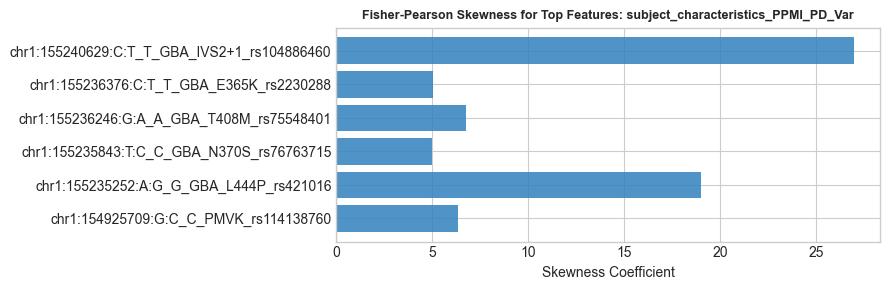

In [13]:
# Load committed unit artifact
unit_json_path = repo_root / "EDA" / "outputs" / "reports" / "units" / "subject_characteristics_PPMI_PD_Variants_Genetic_Status_WGS_20180921_csv.json"
with open(unit_json_path, "r", encoding="utf-8") as f:
    unit_data = json.load(f)

print("=" * 80)
print(f"UNIT ANALYSIS: subject_characteristics/PPMI_PD_Variants_Genetic_Status_WGS_20180921.csv")
print("=" * 80)
print(f"EDA Status: {unit_data['eda_status']} | PCA Status: {unit_data['pca_status']}")

if unit_data.get("eda_status") == "UNREADABLE":
    print(f"UNREADABLE EVIDENCE: {unit_data.get('eda_unreadable_evidence')}")
else:
    eda = unit_data["eda_diagnostics"]
    print(f"Dimensions: {eda['row_count']:,} analyzed rows x {eda['column_count']} columns")
    print(f"Observation Grain: {eda['observation_grain']}")
    print(f"Candidate Primary Keys: {eda.get('candidate_primary_keys', [])}")

    # Cohort Denominator Evidence
    cohort_ev = eda.get("cohort_filter_evidence")
    if cohort_ev and cohort_ev.get("has_participant_data"):
        print("\nTarget Cohort Filtering Denominators:")
        print(f"  - Initial Rows: {cohort_ev.get('total_rows_pre_filter', 0):,} ({cohort_ev.get('distinct_participants_pre_filter', 0):,} participants)")
        print(f"  - PD Retained:  {cohort_ev.get('pd_rows_retained', 0):,} rows ({cohort_ev.get('pd_participants_retained', 0):,} participants)")
        print(f"  - HC Retained:  {cohort_ev.get('hc_rows_retained', 0):,} rows ({cohort_ev.get('hc_participants_retained', 0):,} participants)")
        print(f"  - Non-Target Excluded: {cohort_ev.get('nontarget_rows_excluded', 0):,} rows (SWEDD/Prodromal)")
        print(f"  - Unmatched Excluded:  {cohort_ev.get('unmatched_rows_excluded', 0):,} rows")

    # 1. Exact Column Schema & Types Table
    cols_df = pd.DataFrame(eda["column_profiles"])
    role_col = "variable_role" if "variable_role" in cols_df.columns else "role"
    schema_cols = [c for c in ["name", "dtype", "missing_count", "missing_percent", "distinct_count", role_col] if c in cols_df.columns]
    schema_view = cols_df[schema_cols].copy()
    if "missing_count" in schema_view.columns:
        schema_view["missing_count"] = schema_view["missing_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "distinct_count" in schema_view.columns:
        schema_view["distinct_count"] = schema_view["distinct_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "missing_percent" in schema_view.columns:
        schema_view["missing_percent"] = schema_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v) if pd.notna(v) else "-")

    print(f"\nExact Variable Schema & Storage Types ({len(cols_df)} columns):")
    if len(schema_view) <= 25:
        display(schema_view)
    else:
        print(f"Showing first 20 of {len(schema_view)} columns (complete schema committed to subject_characteristics_PPMI_PD_Variants_Genetic_Status_WGS_20180921_csv.json):")
        display(schema_view.head(20))

    print("\nVariable Role Distribution Summary:")
    display(cols_df[role_col].value_counts().to_frame("Count"))

    # 2. Missingness and Duplicate Quality Evidence
    print(f"\nMissingness & Duplicate Quality Evidence:")
    print(f"  - Total Missing Cells: {eda['total_missing_cells']:,} / {eda['row_count']*eda['column_count']:,} ({eda['overall_missing_percent']:.2f}%)")
    print(f"  - Duplicate Rows Count: {eda['duplicate_rows_count']}")
    high_missing = cols_df[cols_df["missing_percent"] > 0].sort_values("missing_percent", ascending=False)
    if not high_missing.empty:
        print(f"  - Columns with Missing Values ({len(high_missing)} total, top 8):")
        missing_view = high_missing[["name", "missing_count", "missing_percent", role_col]].head(8).copy()
        missing_view["missing_count"] = missing_view["missing_count"].apply(lambda v: "{:,}".format(int(v)))
        missing_view["missing_percent"] = missing_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v))
        display(missing_view)
    else:
        print("  - Zero missing values detected across all columns.")

    # 3. Categorical Variable Frequency Summaries (<5 Suppressed)
    cat_summaries = eda.get("categorical_summaries", [])
    if cat_summaries:
        print(f"\nCategorical Variable Frequency Distributions ({len(cat_summaries)} variables profiled):")
        for cat_item in cat_summaries[:3]:
            var_name = cat_item.get("variable")
            freq_df = pd.DataFrame(cat_item.get("frequencies", []))
            print(f"  * Feature: {var_name} (Distinct Categories: {cat_item.get('distinct_count')})")
            if not freq_df.empty:
                freq_view = freq_df.copy()
                if "category" in freq_view.columns:
                    freq_view["category"] = freq_view["category"].apply(lambda c: "'" + str(c) + "'" if str(c).strip().upper() in ["ID", "PATNO", "SUBJID", "SUBJECT", "PARTICIPANT", "RECORD", "SAMPLE", "CASE", "PID", "RID"] else str(c))
                if "row_count" in freq_view.columns:
                    freq_view["row_count"] = freq_view["row_count"].apply(lambda v: "{:,}".format(int(v)) if isinstance(v, (int, float)) and pd.notna(v) else str(v))
                display(freq_view)
    else:
        print("\nCategorical Frequency Summaries: No multi-level categorical features for this unit.")

    # 4. Outlier and Numeric Summaries (Fisher-Pearson Skewness & Tukey IQR / Z-Score Diagnostics)
    if eda.get("numeric_summaries"):
        num_df = pd.DataFrame(eda["numeric_summaries"])
        print(f"\nNumeric Summaries & Outlier Diagnostics ({len(num_df)} continuous/discrete features):")
        var_col = "variable" if "variable" in num_df.columns else "name"
        cols_to_show = [c for c in [var_col, "mean", "std", "min", "median", "max", "skewness", "shape", "iqr_outliers_count", "zscore_outliers_count"] if c in num_df.columns]
        num_view = num_df[cols_to_show].copy()
        for count_col in ["iqr_outliers_count", "zscore_outliers_count"]:
            if count_col in num_view.columns:
                num_view[count_col] = num_view[count_col].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
        if len(num_view) <= 12:
            display(num_view)
        else:
            print(f"Showing top 10 of {len(num_view)} features (full distribution profiles in subject_characteristics_PPMI_PD_Variants_Genetic_Status_WGS_20180921_csv.json):")
            display(num_view.head(10))

    # 5. Exploratory Data Visualization
    if eda.get("numeric_summaries") and len(eda["numeric_summaries"]) >= 2:
        top_num = pd.DataFrame(eda["numeric_summaries"]).head(6)
        var_col = "variable" if "variable" in top_num.columns else "name"
        fig, ax = plt.subplots(figsize=(9, 3.0))
        ax.barh(top_num[var_col], top_num["skewness"], color="#3182bd", alpha=0.85)
        ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
        ax.set_title(f"Fisher-Pearson Skewness for Top Features: subject_characteristics_PPMI_PD_Var", fontsize=9, fontweight="bold")
        ax.set_xlabel("Skewness Coefficient")
        plt.tight_layout()
        plt.show()
    elif cat_summaries and cat_summaries[0].get("frequencies"):
        first_cat = cat_summaries[0]
        cat_freq_df = pd.DataFrame(first_cat["frequencies"])
        valid_freqs = cat_freq_df[cat_freq_df["row_count"] != "<5 (Suppressed)"].copy()
        if not valid_freqs.empty and len(valid_freqs) >= 2:
            fig, ax = plt.subplots(figsize=(8, 2.5))
            ax.barh(valid_freqs["category"].astype(str), pd.to_numeric(valid_freqs["row_count"]), color="#31a354", alpha=0.85)
            ax.set_title(f"Categorical Frequencies: {first_cat['variable']}", fontsize=9, fontweight="bold")
            ax.set_xlabel("Participant Row Count")
            plt.tight_layout()
            plt.show()

### Principal Component Analysis: Shared-Space Class-Balanced Projection
- **Model Architecture**: One record per participant, fit strictly on balanced sample ($k = \min(N_{PD}, N_{HC})$)
- **Features Retained**: `65` continuous analytical measurements
- **Excluded Features**: `9` variables (identifiers, versions, demographics, codes, staging)
- **Explained Variance**: PC1 explains `10.9%` of shared multivariate variance

Shared-Space PCA Class Denominators:
  - Initial Eligible PD: 534 participants
  - Initial Eligible HC: 194 participants
  - Class-Balanced Fit Size: 194 participants per class (Total Fit N=388)
  - Total Projected Participants: 728


,Component,Individual Variance Ratio,Cumulative Variance Ratio
0,PC1,10.88%,10.88%
1,PC2,3.46%,14.35%
2,PC3,3.04%,17.38%
3,PC4,3.02%,20.40%
4,PC5,2.84%,23.24%



Top PC1 Feature Loadings:


,feature_name,loading
0,chr22:19962429:A:G_G_COMT_rs6269,0.3549
1,chr22:19962905:A:G_G_COMT_rs2239393,0.3548
2,chr22:19962712:C:T_C_COMT_rs4633,0.3527
3,chr22:19963748:G:A_A_COMT_rs4680,-0.3520
4,chr22:19961340:G:C_G_COMT_rs165656,0.3515


Scree & Eigenvector Loadings Plot:


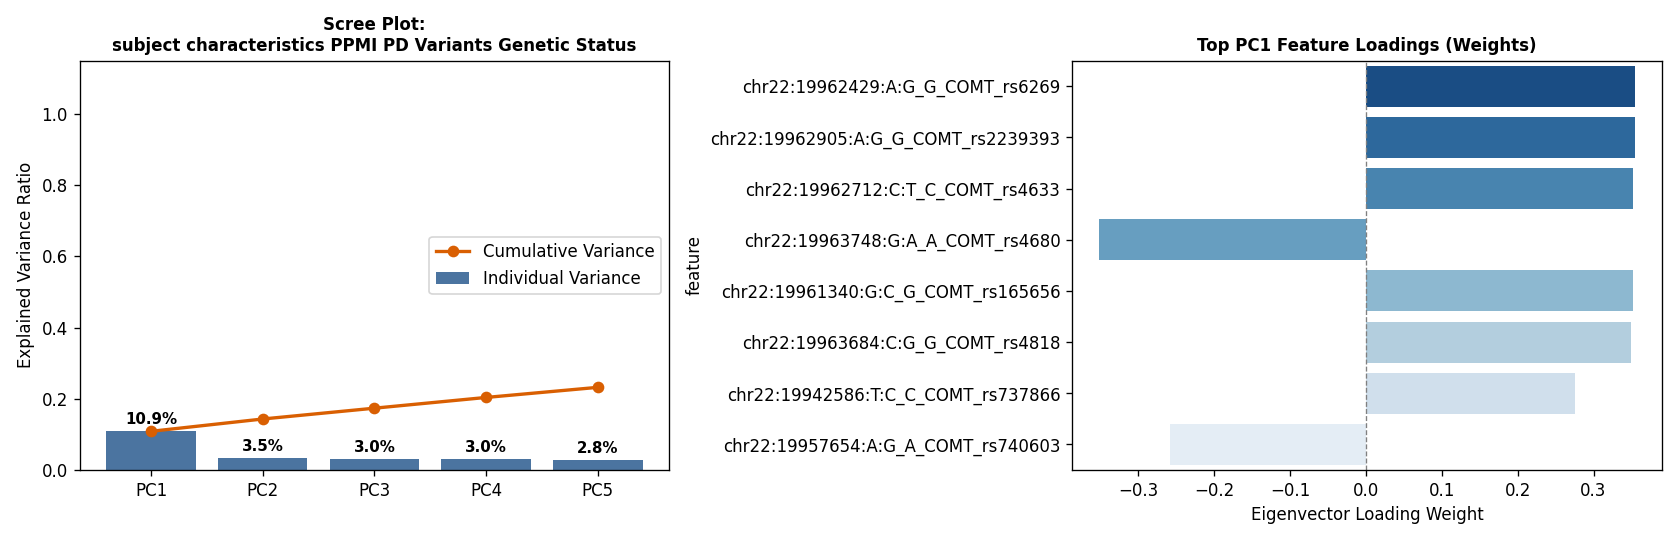

Privacy-Safe Shared-Space Side-by-Side Hexbin Score Density Plot (Cells < 5 Suppressed):


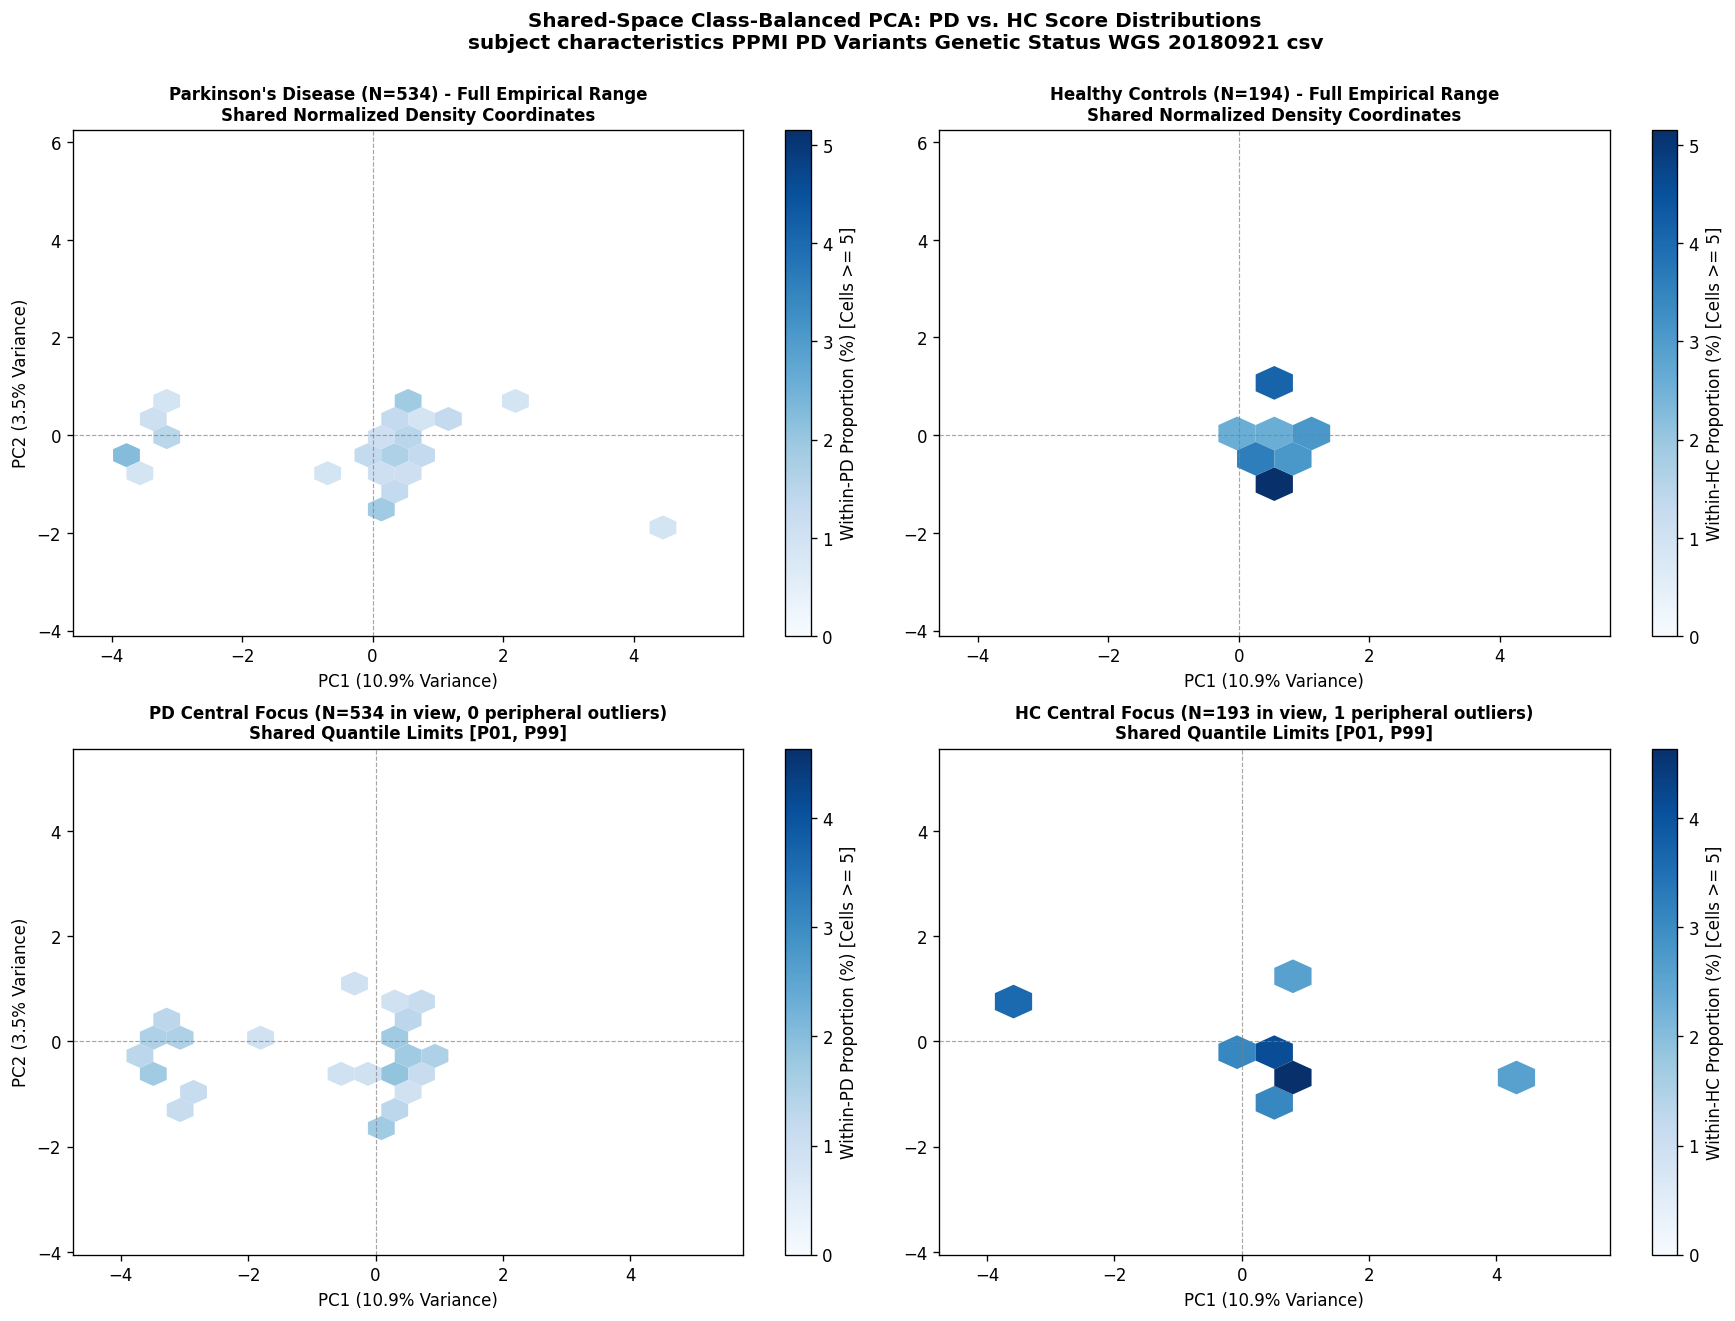

In [14]:
pca_res = unit_data["pca_results"]
c_denom = pca_res.get("class_denominators", {})

print("Shared-Space PCA Class Denominators:")
print(f"  - Initial Eligible PD: {c_denom.get('pd_initial_participants', 0):,} participants")
print(f"  - Initial Eligible HC: {c_denom.get('hc_initial_participants', 0):,} participants")
print(f"  - Class-Balanced Fit Size: {c_denom.get('balanced_fit_size_per_class', 0):,} participants per class (Total Fit N={c_denom.get('total_balanced_fit_observations', 0):,})")
print(f"  - Total Projected Participants: {c_denom.get('total_projected_participants', 0):,}")

# Explained Variance Table
exp_var = pca_res["explained_variance_ratio"]
cum_var = pca_res["cumulative_variance_ratio"]
var_df = pd.DataFrame({
    "Component": [f"PC{i+1}" for i in range(len(exp_var))],
    "Individual Variance Ratio": [f"{v:.2%}" for v in exp_var],
    "Cumulative Variance Ratio": [f"{v:.2%}" for v in cum_var]
})
display(var_df)

# Top PC1 and PC2 Loadings
top_pc1 = pd.DataFrame(pca_res.get("top_loadings_pc1", []))
top_pc2 = pd.DataFrame(pca_res.get("top_loadings_pc2", []))
print("\nTop PC1 Feature Loadings:")
display(top_pc1)

# Display Embedded Figures (Portable Relative Paths)
scree_rel = pca_res.get("scree_plot_path") or "EDA/outputs/reports/figures/scree_loadings/subject_characteristics_PPMI_PD_Variants_Genetic_Status_WGS_20180921_csv_scree_loadings.png"
score_rel = pca_res.get("score_plot_path") or "EDA/outputs/reports/figures/pca_scores/subject_characteristics_PPMI_PD_Variants_Genetic_Status_WGS_20180921_csv_pca_scores.png"
scree_path = repo_root / scree_rel if scree_rel else Path("NO_PATH")
score_path = repo_root / score_rel if score_rel else Path("NO_PATH")

if scree_path.exists():
    print("Scree & Eigenvector Loadings Plot:")
    display(Image(filename=str(scree_path)))

if score_path.exists():
    print("Privacy-Safe Shared-Space Side-by-Side Hexbin Score Density Plot (Cells < 5 Suppressed):")
    display(Image(filename=str(score_path)))

---
## 3. Modality Synthesis & Scientific Limitations

### Evidence-Bounded Findings
- **Data Coverage**: Analysis covered all 6 scoped analyzable unit(s) belonging to `Genetics & Molecular Risk`.
- **Shared Coordinate Space**: All participant-level PCAs were estimated in a deterministically balanced coordinate space combining Parkinson's disease and healthy control cohorts, which reduces direct sample-count influence on component orientation.
- **Variance Patterns**: Scree and loading structures demonstrate dominant sources of numeric variance within the retained continuous feature space for this modality.

### Methodological Limitations
1. **Unadjusted Covariates**: PCA projections represent unadjusted variance; age, sex, and disease duration effects are not regressed out.
2. **Missingness Imputation**: Median imputation fitted exclusively on the class-balanced training sample was applied to replace missing values in retained features (features with > 40% missingness excluded), preserving sample size rather than performing complete-case deletion.
3. **No Causal / Diagnostic Claims**: PCA scores reflect descriptive data geometry and must not be interpreted as validated diagnostic classifiers or clinical progression endpoints without formal hypothesis testing.